# NGS variant calling workflow

<div style="background-color: PaleTurquoise; padding: 10px;">
    
This notebook contains a simple SNP calling workflow.

Please run and explore this workflow.

Areas with questions about QC are highlighted in yellow

</div>

## Case

Two exome sequencing samples of a T-Cell Acute Lymphoblastic Leukemia patient. 

One sample (`TLE66_T`) is of tumor, one healthy control sample  (`TLE66_N`)

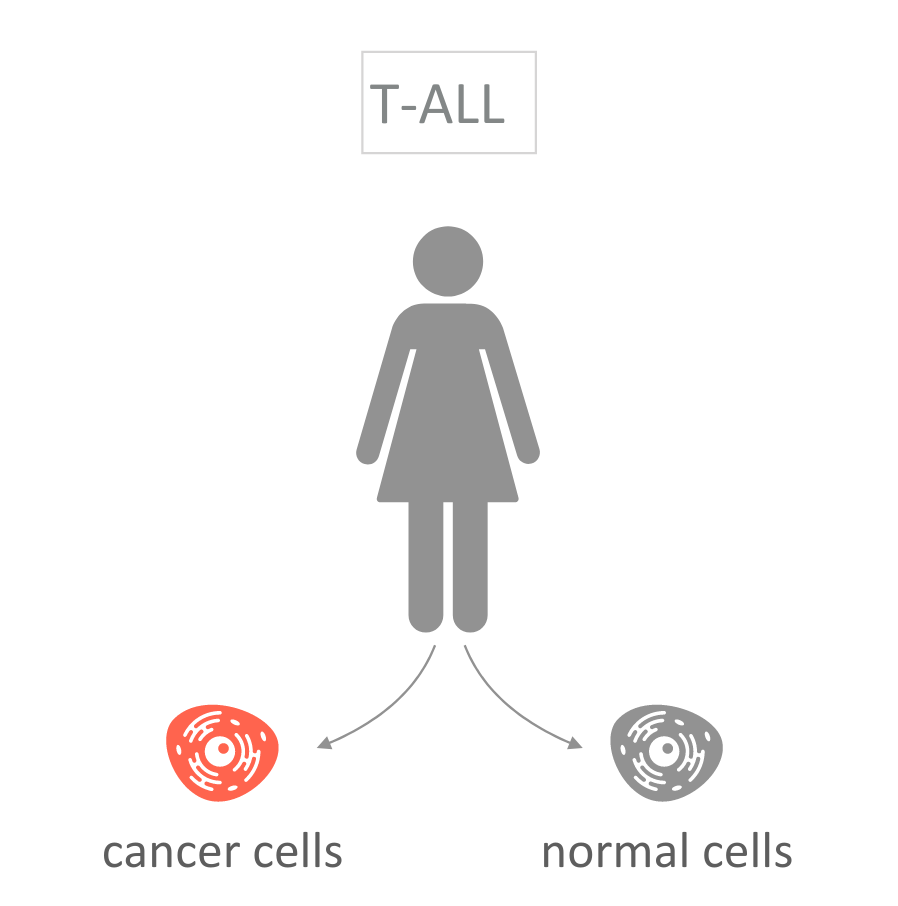

Goal: process the raw fastq, call & annotate SNPs.

We want to ultimately find interesting variants that may be causal to the T-ALL.

## Preparation

In [1]:
echo $VSC_DATA

/data/leuven/381/vsc38194


The cleanest way to work with notebooks is to first create a folder on your server (VSC). For example:

    mkdir $VSC_DATA/variant_calling_manual

- You can do this in the jupyter interface
- Upload your notebook to this folder
- Navigate to this folder from jupyter
- Open the notebook

This ensures you are always working from the correct location. If you did not do this, please shutdown this notebook and do this.

If you do not do this, you are in the wrong folder upon a notebook crash, or when you forget to cd into your workfolder.

In [2]:
# make sure we add our conda environment to the path
# there are also a number of command line tools installed
# You need to do this every time you need to use our conda env.

export PATH=/lustre1/project/stg_00079/teaching/I0U19a_conda_2026/bin/:$PATH

In [3]:
# ensure we are using the correct environment - test with bwa

which bwa

/lustre1/project/stg_00079/teaching/I0U19a_conda_2026/bin/bwa


In [11]:
# create a scratch folder! - Important to check you are working in the correct scratch folder for subsequent workœ
# Make sure you use absolute paths as much as possible - relative paths can give unexpected results.
# image running (`mkdir variant_calling_manual ; cd variant_calling_manual`) twice in a row.

mkdir -p $VSC_SCRATCH/variant_calling_manual
cd $VSC_SCRATCH/variant_calling_manual
pwd
ls

/scratch/leuven/381/vsc38194/variant_calling_manual
61  TLE66_N.fastq  TLE66_T.fastq


In [12]:
# We will be using the genome sequence & index a few times - 
# So I'll use an environment variable

# Note - we are definitely using hg19 for this course.

# To keep memory requirements in check we're using a truncated database with just chromosome 9
DB=/staging/leuven/stg_00079/teaching/hg38_9/chr9.fa

In [13]:
ls -lh $DB

-rw-rw-r--+ 1 vsc30690 lp_edu_large_omics 135M Jan 24  2014 /staging/leuven/stg_00079/teaching/hg38_9/chr9.fa


<div style="background-color: khaki; padding: 10px;">

## Prepare

* What are the version numbers of all tools used in this notebook. Get it from the tools!
* as follows
</div>

In [10]:
bwa 2>&1 | grep Version

Version: 0.7.19-r1273


In [11]:
fastqc -v

FastQC v0.12.1


In [15]:
samtools --version | head -1

samtools 1.23


In [26]:
bcftools --version | head -1

bcftools 1.23


In [21]:
snpEff -version

SnpEff	5.4a	2025-11-25


In [14]:
# Create a symlink to VSC_SCRATCH from $VSC_DATA -
# so that you can inspect your data using the jupyter file browser
ln -sf $VSC_SCRATCH $VSC_DATA/scratch 

In [28]:
ln -sf /staging/leuven/stg_00079/teaching/data_manual_snpcall/*.fastq .
ls -l

total 260
drwxr-x--- 2 vsc38194 vsc38194   4096 Feb 26 14:14 fastqc_output
-rw-r--r-- 1 vsc38194 vsc38194 248175 Mar  1 14:29 manual_snp_calling_workflow.ipynb
lrwxrwxrwx 1 vsc38194 vsc38194     68 Mar  1 14:30 TLE66_N.fastq -> /staging/leuven/stg_00079/teaching/data_manual_snpcall/TLE66_N.fastq
lrwxrwxrwx 1 vsc38194 vsc38194     68 Mar  1 14:30 TLE66_T.fastq -> /staging/leuven/stg_00079/teaching/data_manual_snpcall/TLE66_T.fastq


The `sha256` checksums of these files are supposed to be:

    5ad4bb2f5bd5f6e430b7ab2fff0a164255d4e608363104a75142b6c5a032ddf9  TLE66_N.fastq
    cd9d41d1c0b59a4819fa58007ef796c543b1a7346cb11cceb71ad02d9e2b2cfe  TLE66_T.fastq


<div style="background-color: khaki; padding: 10px;">

## Raw data Quality Control

* Do the checksums match?
* command: sha256sum filename
* Do the raw files look like fastq?
* head TLE66_N.fastq   head TLE66_T.fastq   
* Do they have a reasonable number of reads?
* as follows.   
 
</div>

In [44]:
sha256sum TLE66_N.fastq

5ad4bb2f5bd5f6e430b7ab2fff0a164255d4e608363104a75142b6c5a032ddf9  TLE66_N.fastq


In [45]:
sha256sum TLE66_T.fastq

cd9d41d1c0b59a4819fa58007ef796c543b1a7346cb11cceb71ad02d9e2b2cfe  TLE66_T.fastq


In [39]:
head TLE66_N.fastq

@1121358
TGAATCTGGGAGGCGGAGGTTGCAGTGAGAGTGAGGCGAGATCTCGCCATTGCACTCCAGCCGGGGTGACAAGAG
+
<D<?><DIBB??BF;@;AB@CHG<A?F<@>@;F>>6?8??@@BD,;FF=?DIBD?F;EDAGE8BBC9G?FEBB>@
@1121358
AGCCTCAAACTCCTGGGCTCAAGGGATCCTCACTTCTTGACCTCCCAAAGCGTCATAGGCTTAAGGCACTACAGC
+
A:EFFACACFE?FCG5CG9>C@@B@<@=@FACFEE<F9C>E6FAC+7>:AF=B=A?>B;CG>:<A:<=<B;:0=;
@FCB06B3ABXX:8:1105:13917:3018
TCCCTTGAGCCCAGGAGTTTGAGGCTGCATTGAGCTATGATCATTCCGCTGCACTCCAGCCTGAGTGACAGAGCA


In [46]:
head TLE66_T.fastq

@8884837
CCTATGACGCTTTGGGAGGTCAAGAAGTGAGGATCCCTTGAGCCCAGGAGTTTGAGGCTGCATTGAGCTATGATC
+
=AB?AHBF>GGEEIFFBFFBFDEDBEGAICDGBDDHHHEIBEHHFEEFBFBDFIBGGHFIGCCEB?@GG@AH>A?
@FCD0CAEABXX:4:2104:17216:94349
TGACGCTTTGGGAGGTCAAGAAGTGAGGATCCCTTGAGCCCAGGAGTTTGAGGCTGCATTGAGCTATGATCATTC
+
<C<E;EEDDIID=CDABDBBABCBEAEDAC@GGFDF@AFE<CBB@CBF3H?C;>GEC?@DB/@B9,:@:7>A@7?
@641542
CTCTGGAGGATCCCTTGAGCCCAGGAGTTTGAGGCTGCATTGAGCTATGATCATTCTGCTGCACTCCAGCCTGAG


In [31]:
echo $(cat TLE66_N.fastq | wc -l) / 4 | bc

540624


In [32]:
echo $(cat TLE66_T.fastq | wc -l) / 4 | bc

477888


In [41]:
file -L *

61:                  ASCII text
annotated_snps.vcf:  Variant Call Format (VCF) version 4.2, ASCII text, with very long lines
clean_snps.vcf:      Variant Call Format (VCF) version 4.2, ASCII text, with very long lines
fastqc_output:       directory
raw_snps.vcf:        Variant Call Format (VCF) version 4.2, ASCII text, with very long lines
snpEff_genes.txt:    ASCII text, with very long lines
snpEff_summary.html: HTML document, ASCII text, with very long lines
TLE66_N.bam:         Blocked GNU Zip Format (BGZF; gzip compatible), block length 231
TLE66_N.bam.bai:     SAMtools BAI (BAM indexing format), with 1 reference sequences
TLE66_N.fastq:       ASCII text
TLE66_T.bam:         Blocked GNU Zip Format (BGZF; gzip compatible), block length 223
TLE66_T.bam.bai:     SAMtools BAI (BAM indexing format), with 1 reference sequences
TLE66_T.fastq:       ASCII text


In [16]:
# you can get help using
fastqc --help


            FastQC - A high throughput sequence QC analysis tool

SYNOPSIS

	fastqc seqfile1 seqfile2 .. seqfileN

    fastqc [-o output dir] [--(no)extract] [-f fastq|bam|sam] 
           [-c contaminant file] seqfile1 .. seqfileN

DESCRIPTION

    FastQC reads a set of sequence files and produces from each one a quality
    control report consisting of a number of different modules, each one of 
    which will help to identify a different potential type of problem in your
    data.
    
    If no files to process are specified on the command line then the program
    will start as an interactive graphical application.  If files are provided
    on the command line then the program will run with no user interaction
    required.  In this mode it is suitable for inclusion into a standardised
    analysis pipeline.
    
    The options for the program as as follows:
    
    -h --help       Print this help file and exit
    
    -v --version    Print the version of the program and exit

In [17]:
# Run fastqc - could take a minute or two
mkdir -p fastqc_output
fastqc *.fastq -o fastqc_output

null
null
Started analysis of TLE66_N.fastq
Approx 5% complete for TLE66_N.fastq
Approx 10% complete for TLE66_N.fastq
Approx 15% complete for TLE66_N.fastq
Approx 20% complete for TLE66_N.fastq
Approx 25% complete for TLE66_N.fastq
Approx 30% complete for TLE66_N.fastq
Approx 35% complete for TLE66_N.fastq
Approx 40% complete for TLE66_N.fastq
Approx 45% complete for TLE66_N.fastq
Approx 50% complete for TLE66_N.fastq
Approx 55% complete for TLE66_N.fastq
Approx 60% complete for TLE66_N.fastq
Approx 65% complete for TLE66_N.fastq
Approx 70% complete for TLE66_N.fastq
Approx 75% complete for TLE66_N.fastq
Approx 80% complete for TLE66_N.fastq
Approx 85% complete for TLE66_N.fastq
Approx 90% complete for TLE66_N.fastq
Approx 95% complete for TLE66_N.fastq
Analysis complete for TLE66_N.fastq
Started analysis of TLE66_T.fastq
Approx 5% complete for TLE66_T.fastq
Approx 10% complete for TLE66_T.fastq
Approx 15% complete for TLE66_T.fastq
Approx 20% complete for TLE66_T.fastq
Approx 25% com

Back in your jupyter browser you can see the html & zip outputs

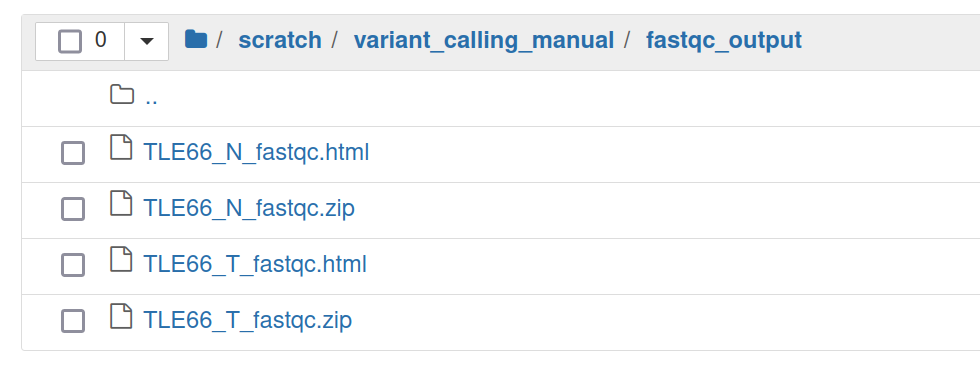


<div style="background-color: khaki; padding: 10px;">

## Fastq data Quality Control

* Is the quality ok?
* Yes, the quality is good. Based on the FastQC reports, nearly all modules passed with green (OK) status, and the per-base quality scores are consistently high (Q35+).
* How is the quality score encoded? Do you need to take this into account?
* According to the FastQC reports, the quality scores are encoded using the Sanger / Illumina 1.9 format. This is the modern standard and is automatically recognized by downstream tools like bwa and samtools, so we do not need to take any special action. FastQC has already handled the interpretation for us in the report.
 
</div>

## Align the reads

We will be using `bwa mem`. Get help by running without arguments

In [37]:
bwa mem || true


Usage: bwa mem [options] <idxbase> <in1.fq> [in2.fq]

Algorithm options:

       -t INT        number of threads [1]
       -k INT        minimum seed length [19]
       -w INT        band width for banded alignment [100]
       -d INT        off-diagonal X-dropoff [100]
       -r FLOAT      look for internal seeds inside a seed longer than {-k} * FLOAT [1.5]
       -y INT        seed occurrence for the 3rd round seeding [20]
       -c INT        skip seeds with more than INT occurrences [500]
       -D FLOAT      drop chains shorter than FLOAT fraction of the longest overlapping chain [0.50]
       -W INT        discard a chain if seeded bases shorter than INT [0]
       -m INT        perform at most INT rounds of mate rescues for each read [50]
       -S            skip mate rescue
       -P            skip pairing; mate rescue performed unless -S also in use

Scoring options:

       -A INT        score for a sequence match, which scales options -TdBOELU unless overridden [1]
     

In [38]:
echo ${DB}

In [20]:
bwa mem ${DB} TLE66_N.fastq | samtools sort -o TLE66_N.bam -

[M::bwa_idx_load_from_disk] read 0 ALT contigs
[M::process] read 133334 sequences (10000050 bp)...
[M::process] read 133334 sequences (10000050 bp)...
[M::mem_process_seqs] Processed 133334 reads in 2.901 CPU sec, 2.907 real sec
[M::process] read 133334 sequences (10000050 bp)...
[M::mem_process_seqs] Processed 133334 reads in 3.267 CPU sec, 3.323 real sec
[M::process] read 133334 sequences (10000050 bp)...
[M::mem_process_seqs] Processed 133334 reads in 3.228 CPU sec, 3.277 real sec
[M::process] read 7288 sequences (546600 bp)...
[M::mem_process_seqs] Processed 133334 reads in 4.072 CPU sec, 4.122 real sec
[M::mem_process_seqs] Processed 7288 reads in 0.259 CPU sec, 0.303 real sec
[main] Version: 0.7.19-r1273
[main] CMD: bwa mem /staging/leuven/stg_00079/teaching/hg38_9/chr9.fa TLE66_N.fastq
[main] Real time: 14.081 sec; CPU: 13.868 sec


In [21]:
bwa mem ${DB} TLE66_T.fastq | samtools sort - > TLE66_T.bam

[M::bwa_idx_load_from_disk] read 0 ALT contigs
[M::process] read 133334 sequences (10000050 bp)...
[M::process] read 133334 sequences (10000050 bp)...
[M::mem_process_seqs] Processed 133334 reads in 2.916 CPU sec, 2.930 real sec
[M::process] read 133334 sequences (10000050 bp)...
[M::mem_process_seqs] Processed 133334 reads in 3.213 CPU sec, 3.262 real sec
[M::process] read 77886 sequences (5841450 bp)...
[M::mem_process_seqs] Processed 133334 reads in 3.302 CPU sec, 3.366 real sec
[M::mem_process_seqs] Processed 77886 reads in 2.687 CPU sec, 2.740 real sec
[main] Version: 0.7.19-r1273
[main] CMD: bwa mem /staging/leuven/stg_00079/teaching/hg38_9/chr9.fa TLE66_T.fastq
[main] Real time: 12.479 sec; CPU: 12.272 sec


In [22]:
# create indici
samtools index TLE66_N.bam
samtools index TLE66_T.bam

In [6]:
cd $VSC_SCRATCH/variant_calling_manual

In [7]:
pwd
ls -l

/scratch/leuven/381/vsc38194/variant_calling_manual
total 70840
-rw-r----- 1 vsc38194 vsc38194     1200 Feb 26 14:47 61
-rw-r----- 1 vsc38194 vsc38194  1775439 Feb 26 14:34 annotated_snps.vcf
-rw-r----- 1 vsc38194 vsc38194   567832 Feb 26 14:33 clean_snps.vcf
drwxr-x--- 3 vsc38194 vsc38194     4096 Feb 26 14:16 fastqc_output
-rw-r----- 1 vsc38194 vsc38194   982232 Feb 26 14:25 raw_snps.vcf
-rw-r----- 1 vsc38194 vsc38194    43281 Feb 26 14:34 snpEff_genes.txt
-rw-r----- 1 vsc38194 vsc38194   230498 Feb 26 14:34 snpEff_summary.html
-rw-r----- 1 vsc38194 vsc38194 36321020 Feb 26 14:17 TLE66_N.bam
-rw-r----- 1 vsc38194 vsc38194    80208 Feb 26 14:18 TLE66_N.bam.bai
lrwxrwxrwx 1 vsc38194 vsc38194       68 Feb 26 14:15 TLE66_N.fastq -> /staging/leuven/stg_00079/teaching/data_manual_snpcall/TLE66_N.fastq
-rw-r----- 1 vsc38194 vsc38194 32427184 Feb 26 14:17 TLE66_T.bam
-rw-r----- 1 vsc38194 vsc38194    79776 Feb 26 14:18 TLE66_T.bam.bai
lrwxrwxrwx 1 vsc38194 vsc38194       68 Feb 26 14:15 TLE6

<div style="background-color: khaki; padding: 10px;">

## BAM  Quality control

* Did all tools finish without error?
* Yes
* Is the header correct? (Use `samtools view -H`)
* Yes.as follows.
* Do the files look like BAM? (Use `samtools view ... | head`)
* To which chromosomes to the reads map? (Use `samtools idxstats`) What do you expect?
* The reads map to chromosome 9, which is expected because because we're using a truncated database with just chromosome 9
* How many & what percentage of the reads map properly? (Use `samtools flagstat`)
* For TLE66_N:540,563 out of 540,661 reads are mapped, which is 99.98%.
* For TLE66_T:477,793 out of 477,918 reads are mapped, which is 99.97%.
* Download the bam & bai files to disk & visualize in [IGV](https://igv.org/app/). Copy/paste a screenshot.
* 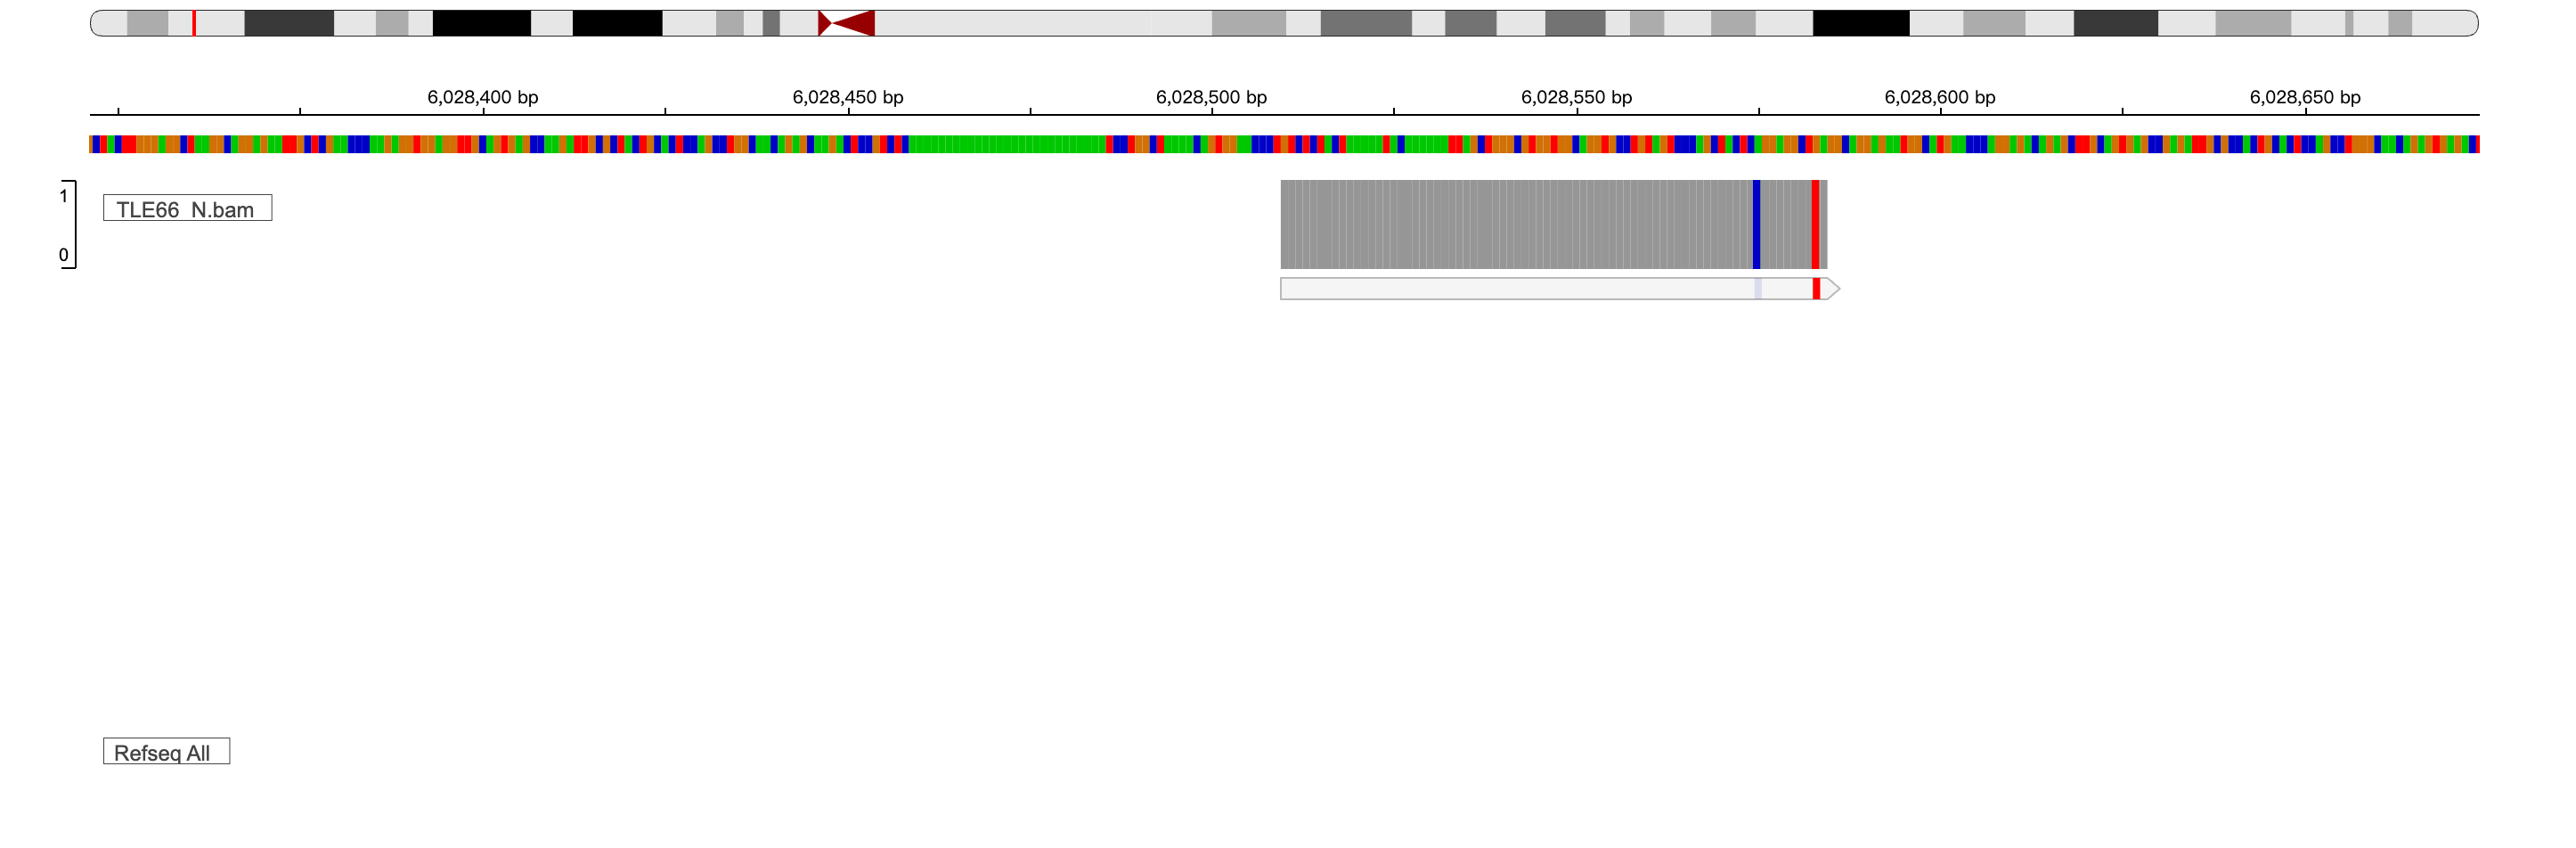
* 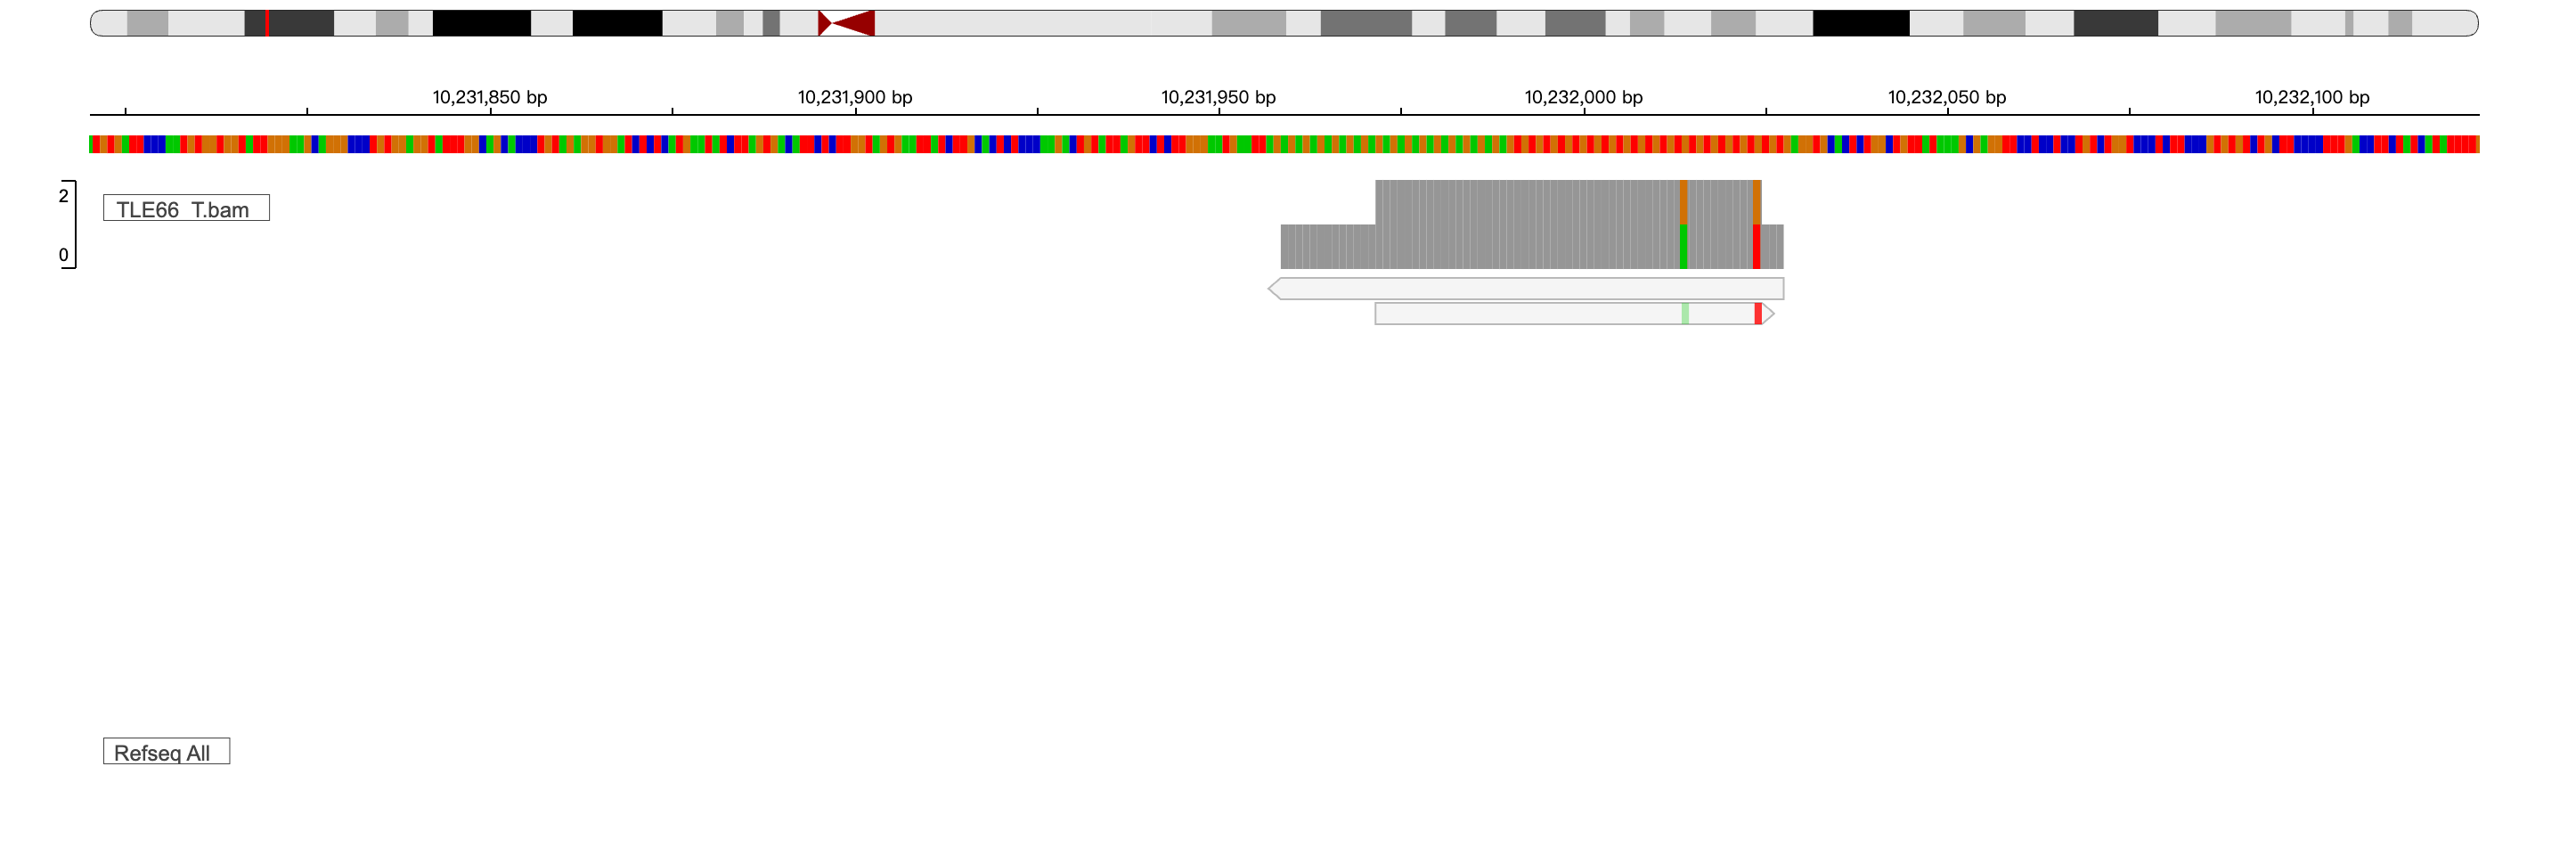
* 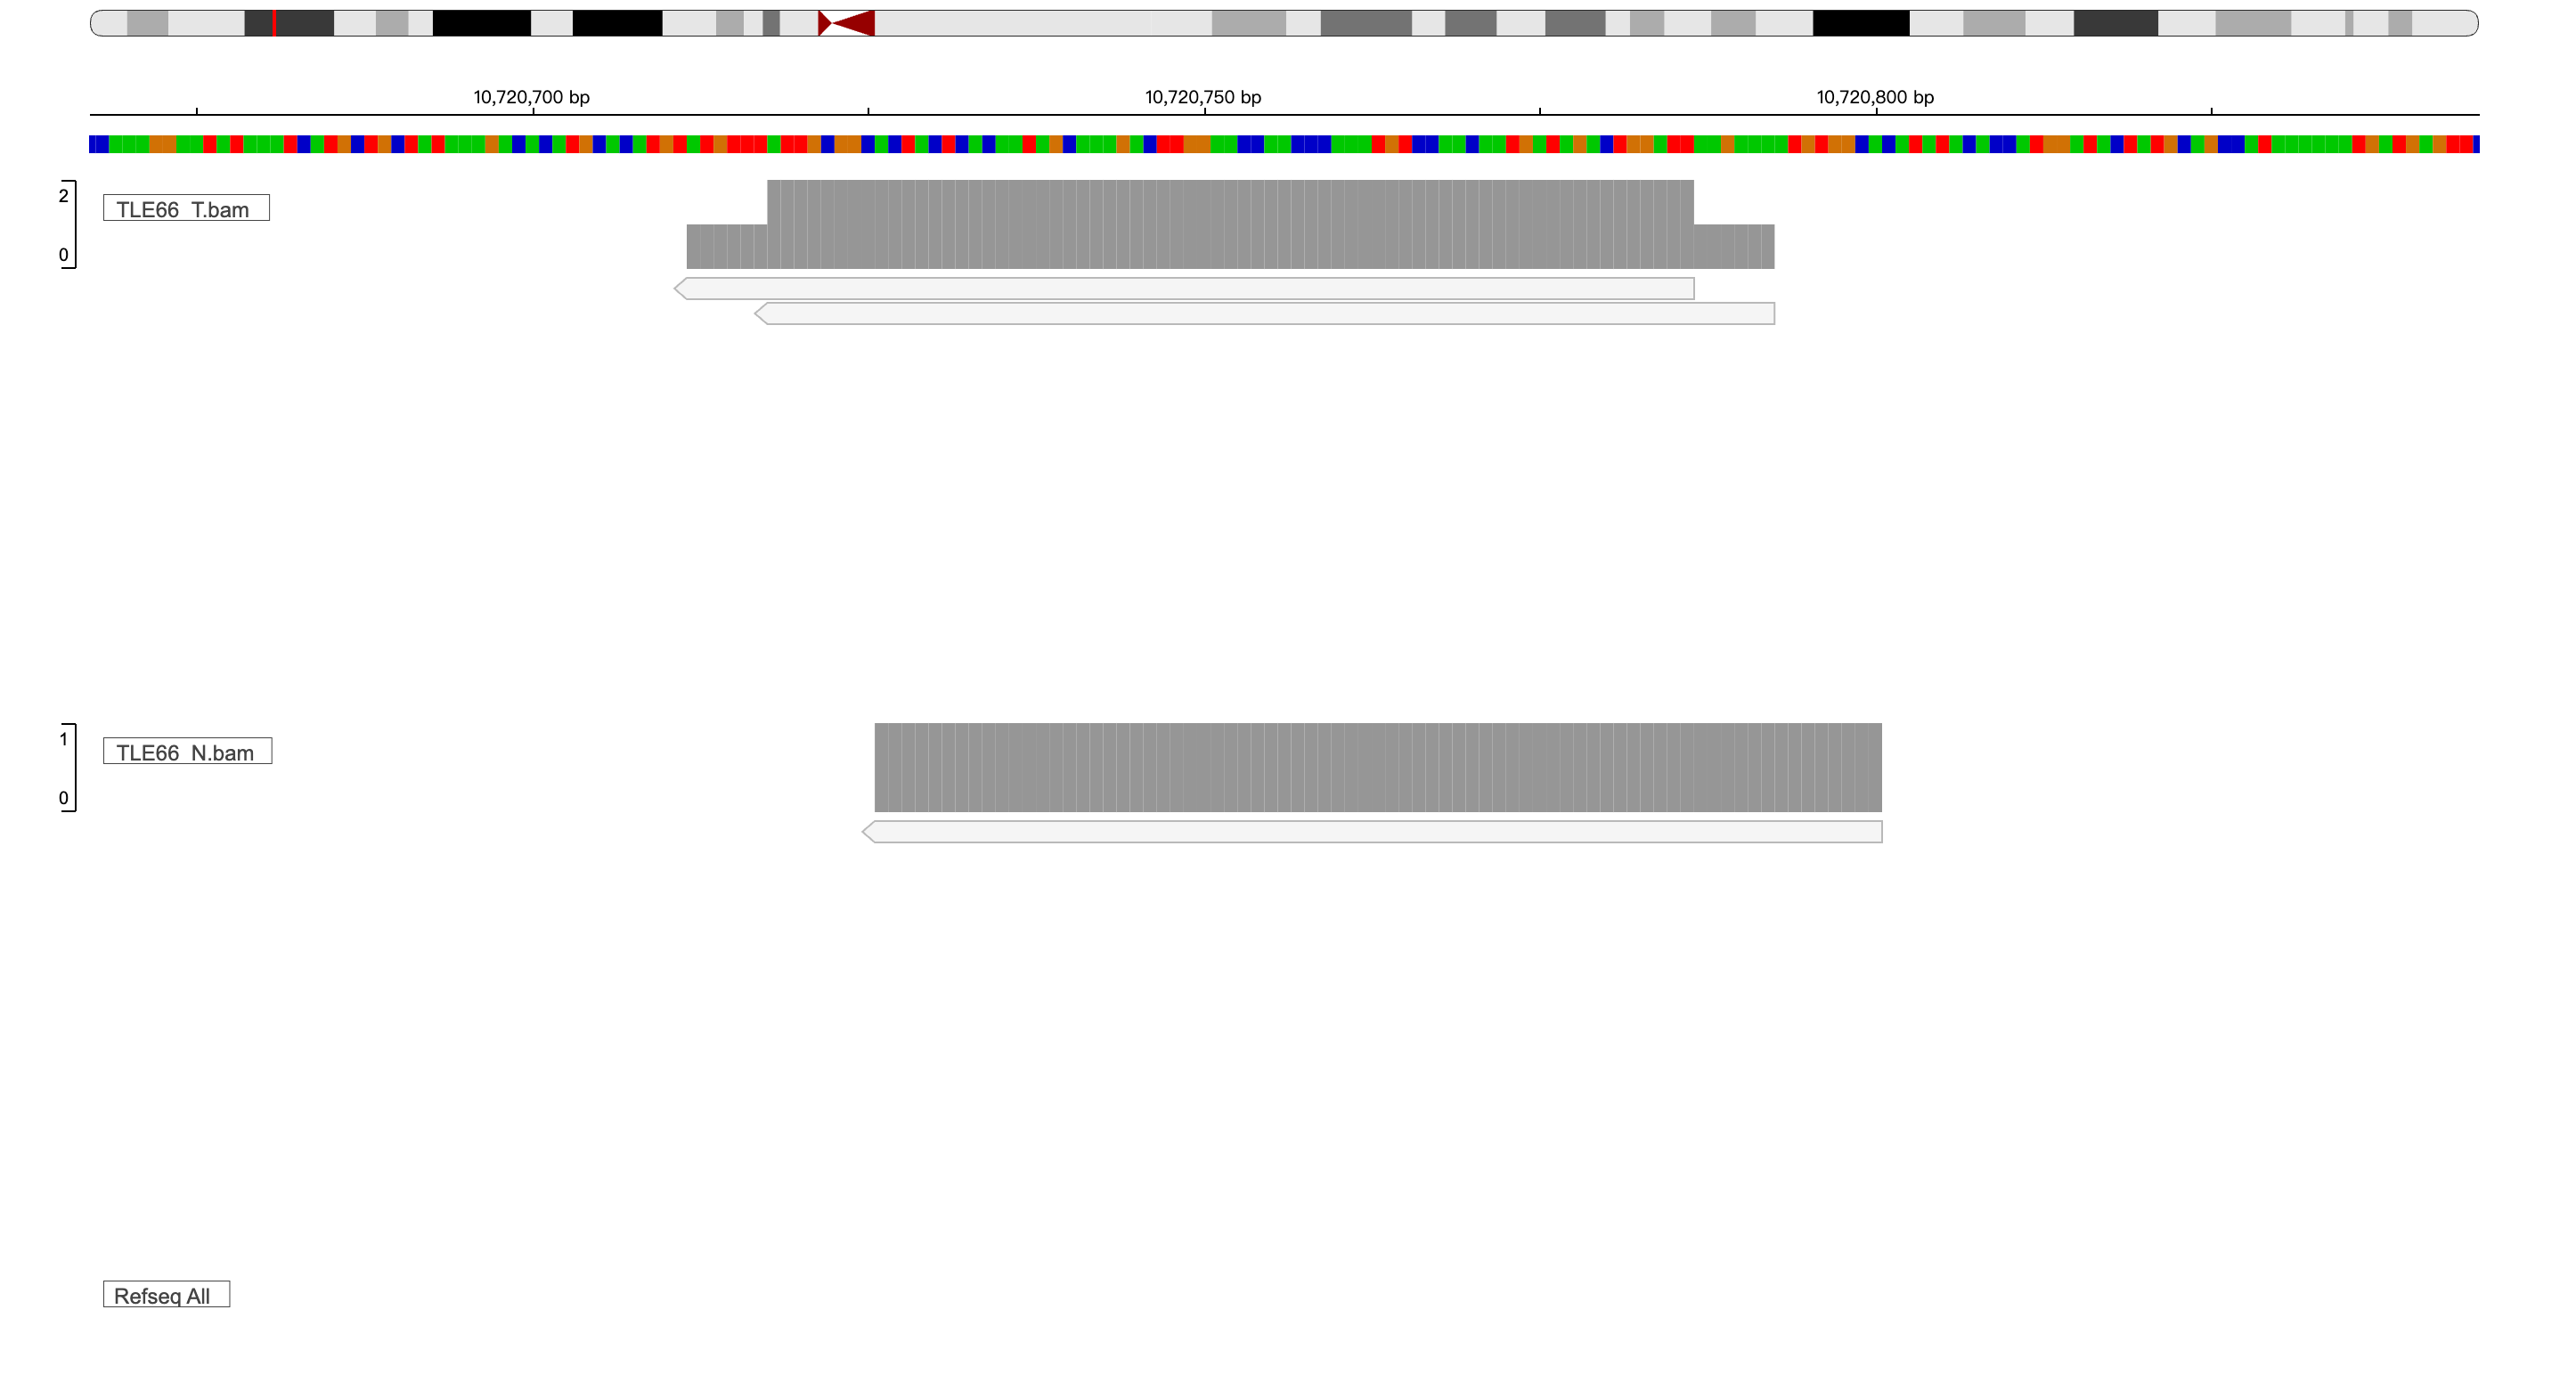
</div>

In [43]:
samtools view -H TLE66_N.bam

@HD	VN:1.5	SO:coordinate
@SQ	SN:chr9	LN:138394717
@PG	ID:bwa	PN:bwa	VN:0.7.19-r1273	CL:bwa mem /staging/leuven/stg_00079/teaching/hg38_9/chr9.fa TLE66_N.fastq
@PG	ID:samtools	PN:samtools	PP:bwa	VN:1.23	CL:samtools sort -o TLE66_N.bam -
@PG	ID:samtools.1	PN:samtools	PP:samtools	VN:1.23	CL:samtools view -H TLE66_N.bam


In [44]:
samtools view -H TLE66_T.bam

@HD	VN:1.5	SO:coordinate
@SQ	SN:chr9	LN:138394717
@PG	ID:bwa	PN:bwa	VN:0.7.19-r1273	CL:bwa mem /staging/leuven/stg_00079/teaching/hg38_9/chr9.fa TLE66_T.fastq
@PG	ID:samtools	PN:samtools	PP:bwa	VN:1.23	CL:samtools sort -
@PG	ID:samtools.1	PN:samtools	PP:samtools	VN:1.23	CL:samtools view -H TLE66_T.bam


In [45]:
samtools view TLE66_N.bam | head

FCB06B3ABXX:8:2108:12853:63847	16	chr9	150174	0	75M	*	0	0	TGGAGTGCAGTGGTGCGATCTCAGCTCACTGCAAGCTCCGCCTCCCGGGTTCACGCCATTCTCCTGCCTCAGCCT	GGDGI/HJHI2IG>F=C=>CBJ7HD@HCC<EDFHHC8E=<EDBEE?IIIDBIC@HGJDECFAGFEIFFBJHGBED	NM:i:0	MD:Z:75	AS:i:75	XS:i:75
3320565	16	chr9	243917	0	75M	*	0	0	GCTCATGCCTGCAATCCCAGCACTTTGGGAGGCCGAGGCGGGCAGATCACGAGGTCAGGAGATCGAGACCATCCT	FDBIAEIGGEHIFBCEEIHHIADCEDHHFFHHF?FGHG?HHGIFECBIB?EFGGAIGHEFEBB?EFEAFIBAEDC	NM:i:1	MD:Z:11T63	AS:i:70	XS:i:70
6131457	0	chr9	532265	6	6S62M7S	*	0	0	CGGACGGAGTTTCACTCTTGGTGCCCACGCTGGAGTGCAGTGGCACCATCTCGGCTCACCGCAACCTCCACCTCC	=:A?E>EADADDEDFFEFDIEBHGG<C>7EGI<>A<FBAA:G?CBFB=???:764:346)28?2<<;*829<?>;	NM:i:2	MD:Z:14T6G40	AS:i:52	XS:i:48
5427388	0	chr9	741463	33	19S43M13S	*	0	0	CTGCACTCTAGCTGGGACCACAGGCACACACCACCACACCTGGCTTTTTTTTTTTTTTTTTTTAGTTGGGGTCCC	=AEDBEEDEAEGFHCEBGGDFDBBGDGDFDFFDGGBGDGGGIFGFEEEEEEEEEEEEEEED@#############	NM:i:0	MD:Z:43	AS:i:43	XS:i:37	XA:Z:chr9,+78228023,7S52M16S,3;
8177811	16	chr9	4648431	0	75M	*	0	0	GGCTCACGCCTGTAATCCCA

In [51]:
samtools view TLE66_T.bam | head

FCD0CAEABXX:4:2208:10782:61918	0	chr9	2695018	0	9S66M	*	0	0	GCCCAGATGACTTTTTGTATTTTTAGTAGAGACGGGGTTTCACCGTGTTAGCCAGGATGGTCTCGATCTCCTGAC	DGGGEFBAJBHGFFFFIBBDFFFECFBCD?EAH@EFF?FEBEGG>BJCFDA@GFECBCJ@CG?DACCEIBJIKBJ	NM:i:0	MD:Z:66	AS:i:66	XS:i:66
FCB06B3ABXX:8:1205:11248:181344	16	chr9	3987463	0	75M	*	0	0	AGGCCAAGGCGGGTGGATCACCTGAGGTCAGGAGTTCGAGACCAGCCTGGCCAACATGGTGAAACCCTGTCTCTA	DEFEGE*>F6>B>EE@<AH>EC@CGHB@JHG>G@EA<CF@=EIGFDCEGGCEEBAABGGECFE@FFBDHAD>C@C	NM:i:0	MD:Z:75	AS:i:75	XS:i:75
FCB06B3ABXX:8:2206:6514:72357	16	chr9	3987464	0	75M	*	0	0	GGCCAAGGCGGGTGGATCACCTGAGGTCAGGAGTTCGAGACCAGCCTGGCCAACATGGTGAAACCCTGTCTCTAC	F;DFF?IC9FH?EGBAAEAFB/BEGFADFGBE@B<:=EA>CIGGEDDHHGIFBIDDHHCBEE@FDDDGAE@C=<=	NM:i:0	MD:Z:75	AS:i:75	XS:i:75
7766436	2048	chr9	7612672	0	31M44H	*	0	0	TTCAAGCGATTCTCTTGTCTCAGCCTCCCAA	=?AACEG?@CEFGFGEIAFGFDGHHGGGHEE	NM:i:0	MD:Z:31	AS:i:31	XS:i:31	SA:Z:chr9,137100869,+,18S57M,0,0;
FCD0CAEABXX:4:1107:9563:74859	16	chr9	10231959	0	4S69M2S	*	0	0	AAAAAGAGAGAGAGAGAGAGAGAGAGAGAGAGAGAGTGTG

In [46]:
samtools idxstats TLE66_N.bam

chr9	138394717	540563	0
*	0	0	98


In [48]:
samtools flagstat TLE66_N.bam

540661 + 0 in total (QC-passed reads + QC-failed reads)
540624 + 0 primary
0 + 0 secondary
37 + 0 supplementary
0 + 0 duplicates
0 + 0 primary duplicates
540563 + 0 mapped (99.98% : N/A)
540526 + 0 primary mapped (99.98% : N/A)
0 + 0 paired in sequencing
0 + 0 read1
0 + 0 read2
0 + 0 properly paired (N/A : N/A)
0 + 0 with itself and mate mapped
0 + 0 singletons (N/A : N/A)
0 + 0 with mate mapped to a different chr
0 + 0 with mate mapped to a different chr (mapQ>=5)


In [47]:
samtools idxstats TLE66_T.bam

chr9	138394717	477793	0
*	0	0	125


In [49]:
samtools flagstat TLE66_T.bam

477918 + 0 in total (QC-passed reads + QC-failed reads)
477888 + 0 primary
0 + 0 secondary
30 + 0 supplementary
0 + 0 duplicates
0 + 0 primary duplicates
477793 + 0 mapped (99.97% : N/A)
477763 + 0 primary mapped (99.97% : N/A)
0 + 0 paired in sequencing
0 + 0 read1
0 + 0 read2
0 + 0 properly paired (N/A : N/A)
0 + 0 with itself and mate mapped
0 + 0 singletons (N/A : N/A)
0 + 0 with mate mapped to a different chr
0 + 0 with mate mapped to a different chr (mapQ>=5)


## SNP Calling

Using bcftools

In [24]:
#get help
bcftools mpileup || true


Usage: bcftools mpileup [options] in1.bam [in2.bam [...]]

Input options:
  -6, --illumina1.3+      Quality is in the Illumina-1.3+ encoding
  -A, --count-orphans     Include anomalous read pairs, with flag PAIRED but not PROPER_PAIR set
  -b, --bam-list FILE     List of input BAM filenames, one per line
  -B, --no-BAQ            Disable BAQ (per-Base Alignment Quality)
  -C, --adjust-MQ INT     Adjust mapping quality [0]
  -D, --full-BAQ          Apply BAQ everywhere, not just in problematic regions
  -d, --max-depth INT     Max raw per-file depth; avoids excessive memory usage [250]
  -E, --redo-BAQ          Recalculate BAQ on the fly, ignore existing BQs
  -f, --fasta-ref FILE    Faidx indexed reference sequence file
      --no-reference      Do not require fasta reference file
  -G, --read-groups FILE  Select or exclude read groups listed in the file
  -q, --min-MQ INT        Skip alignments with mapQ smaller than INT [0]
  -Q, --min-BQ INT        Skip bases with baseQ/BAQ smaller

In [25]:
bcftools mpileup -Ou -f ${DB} TLE66_N.bam TLE66_T.bam \
    | bcftools call -mv -Ov -o raw_snps.vcf

Note: none of --samples-file, --ploidy or --ploidy-file given, assuming all sites are diploid
[mpileup] 2 samples in 2 input files
[mpileup] maximum number of reads per input file set to -d 250


In [26]:
ls

61	       raw_snps.vcf  TLE66_N.bam.bai  TLE66_T.bam      TLE66_T.fastq
fastqc_output  TLE66_N.bam   TLE66_N.fastq    TLE66_T.bam.bai


In [27]:
head raw_snps.vcf

##fileformat=VCFv4.2
##FILTER=<ID=PASS,Description="All filters passed">
##bcftoolsVersion=1.23+htslib-1.23
##bcftoolsCommand=mpileup -Ou -f /staging/leuven/stg_00079/teaching/hg38_9/chr9.fa TLE66_N.bam TLE66_T.bam
##reference=file:///staging/leuven/stg_00079/teaching/hg38_9/chr9.fa
##contig=<ID=chr9,length=138394717>
##ALT=<ID=*,Description="Represents allele(s) other than observed.">
##INFO=<ID=INDEL,Number=0,Type=Flag,Description="Indicates that the variant is an INDEL.">
##INFO=<ID=IDV,Number=1,Type=Integer,Description="Maximum number of raw reads supporting an indel">
##INFO=<ID=IMF,Number=1,Type=Float,Description="Maximum fraction of raw reads supporting an indel">


In [28]:
grep  '^#' raw_snps.vcf | tail

##FORMAT=<ID=PL,Number=G,Type=Integer,Description="List of Phred-scaled genotype likelihoods">
##FORMAT=<ID=AD,Number=R,Type=Integer,Description="Allelic depths (high-quality bases)">
##FORMAT=<ID=GT,Number=1,Type=String,Description="Genotype">
##INFO=<ID=AC,Number=A,Type=Integer,Description="Allele count in genotypes for each ALT allele, in the same order as listed">
##INFO=<ID=AN,Number=1,Type=Integer,Description="Total number of alleles in called genotypes">
##INFO=<ID=DP4,Number=4,Type=Integer,Description="Number of high-quality ref-forward , ref-reverse, alt-forward and alt-reverse bases">
##INFO=<ID=MQ,Number=1,Type=Integer,Description="Average mapping quality">
##bcftools_callVersion=1.23+htslib-1.23
##bcftools_callCommand=call -mv -Ov -o raw_snps.vcf; Date=Thu Feb 26 14:25:42 2026
#CHROM	POS	ID	REF	ALT	QUAL	FILTER	INFO	FORMAT	TLE66_N.bam	TLE66_T.bam


In [29]:
grep -v '^#' raw_snps.vcf | head -5

chr9	34082802	.	C	T	13.2571	.	DP=2;VDB=0.02;SGB=0.0985265;MQ0F=0;AC=2;AN=2;DP4=0,0,0,2;MQ=22	GT:PL:AD	./.:0,0,0:0,0	1/1:40,6,0:0,2
chr9	34082803	.	A	G	13.2571	.	DP=2;VDB=0.02;SGB=0.0985265;MQ0F=0;AC=2;AN=2;DP4=0,0,0,2;MQ=22	GT:PL:AD	./.:0,0,0:0,0	1/1:40,6,0:0,2
chr9	34082813	.	C	G	13.2571	.	DP=2;VDB=0.02;SGB=0.0985265;MQ0F=0;AC=2;AN=2;DP4=0,0,0,2;MQ=22	GT:PL:AD	./.:0,0,0:0,0	1/1:40,6,0:0,2
chr9	34082814	.	C	T	13.2571	.	DP=2;VDB=0.02;SGB=0.0985265;MQ0F=0;AC=2;AN=2;DP4=0,0,0,2;MQ=22	GT:PL:AD	./.:0,0,0:0,0	1/1:40,6,0:0,2
chr9	35641185	.	C	T	8.68025	.	DP=1;SGB=-0.157211;MQ0F=0;AC=2;AN=2;DP4=0,0,1,0;MQ=35	GT:PL:AD	1/1:35,3,0:0,1	./.:0,0,0:0,0


<div style="background-color: khaki; padding: 10px;">

## VCF/bcftools Quality control

* Did all tools finish without error?
* Yes
* Is the file structure correct? (no lines, start, end, header, etc)
* Yes
* Find a high quality SNP (awk, sort, excel, whatever you like). Discuss the criteria.
* chr9:137102481 T>G.The criteria is the high quality with the high coverage depth.
* Attempt to find a variants that are different between the two samples (awk?). Check in IGV, copy/paste screenshot.
* 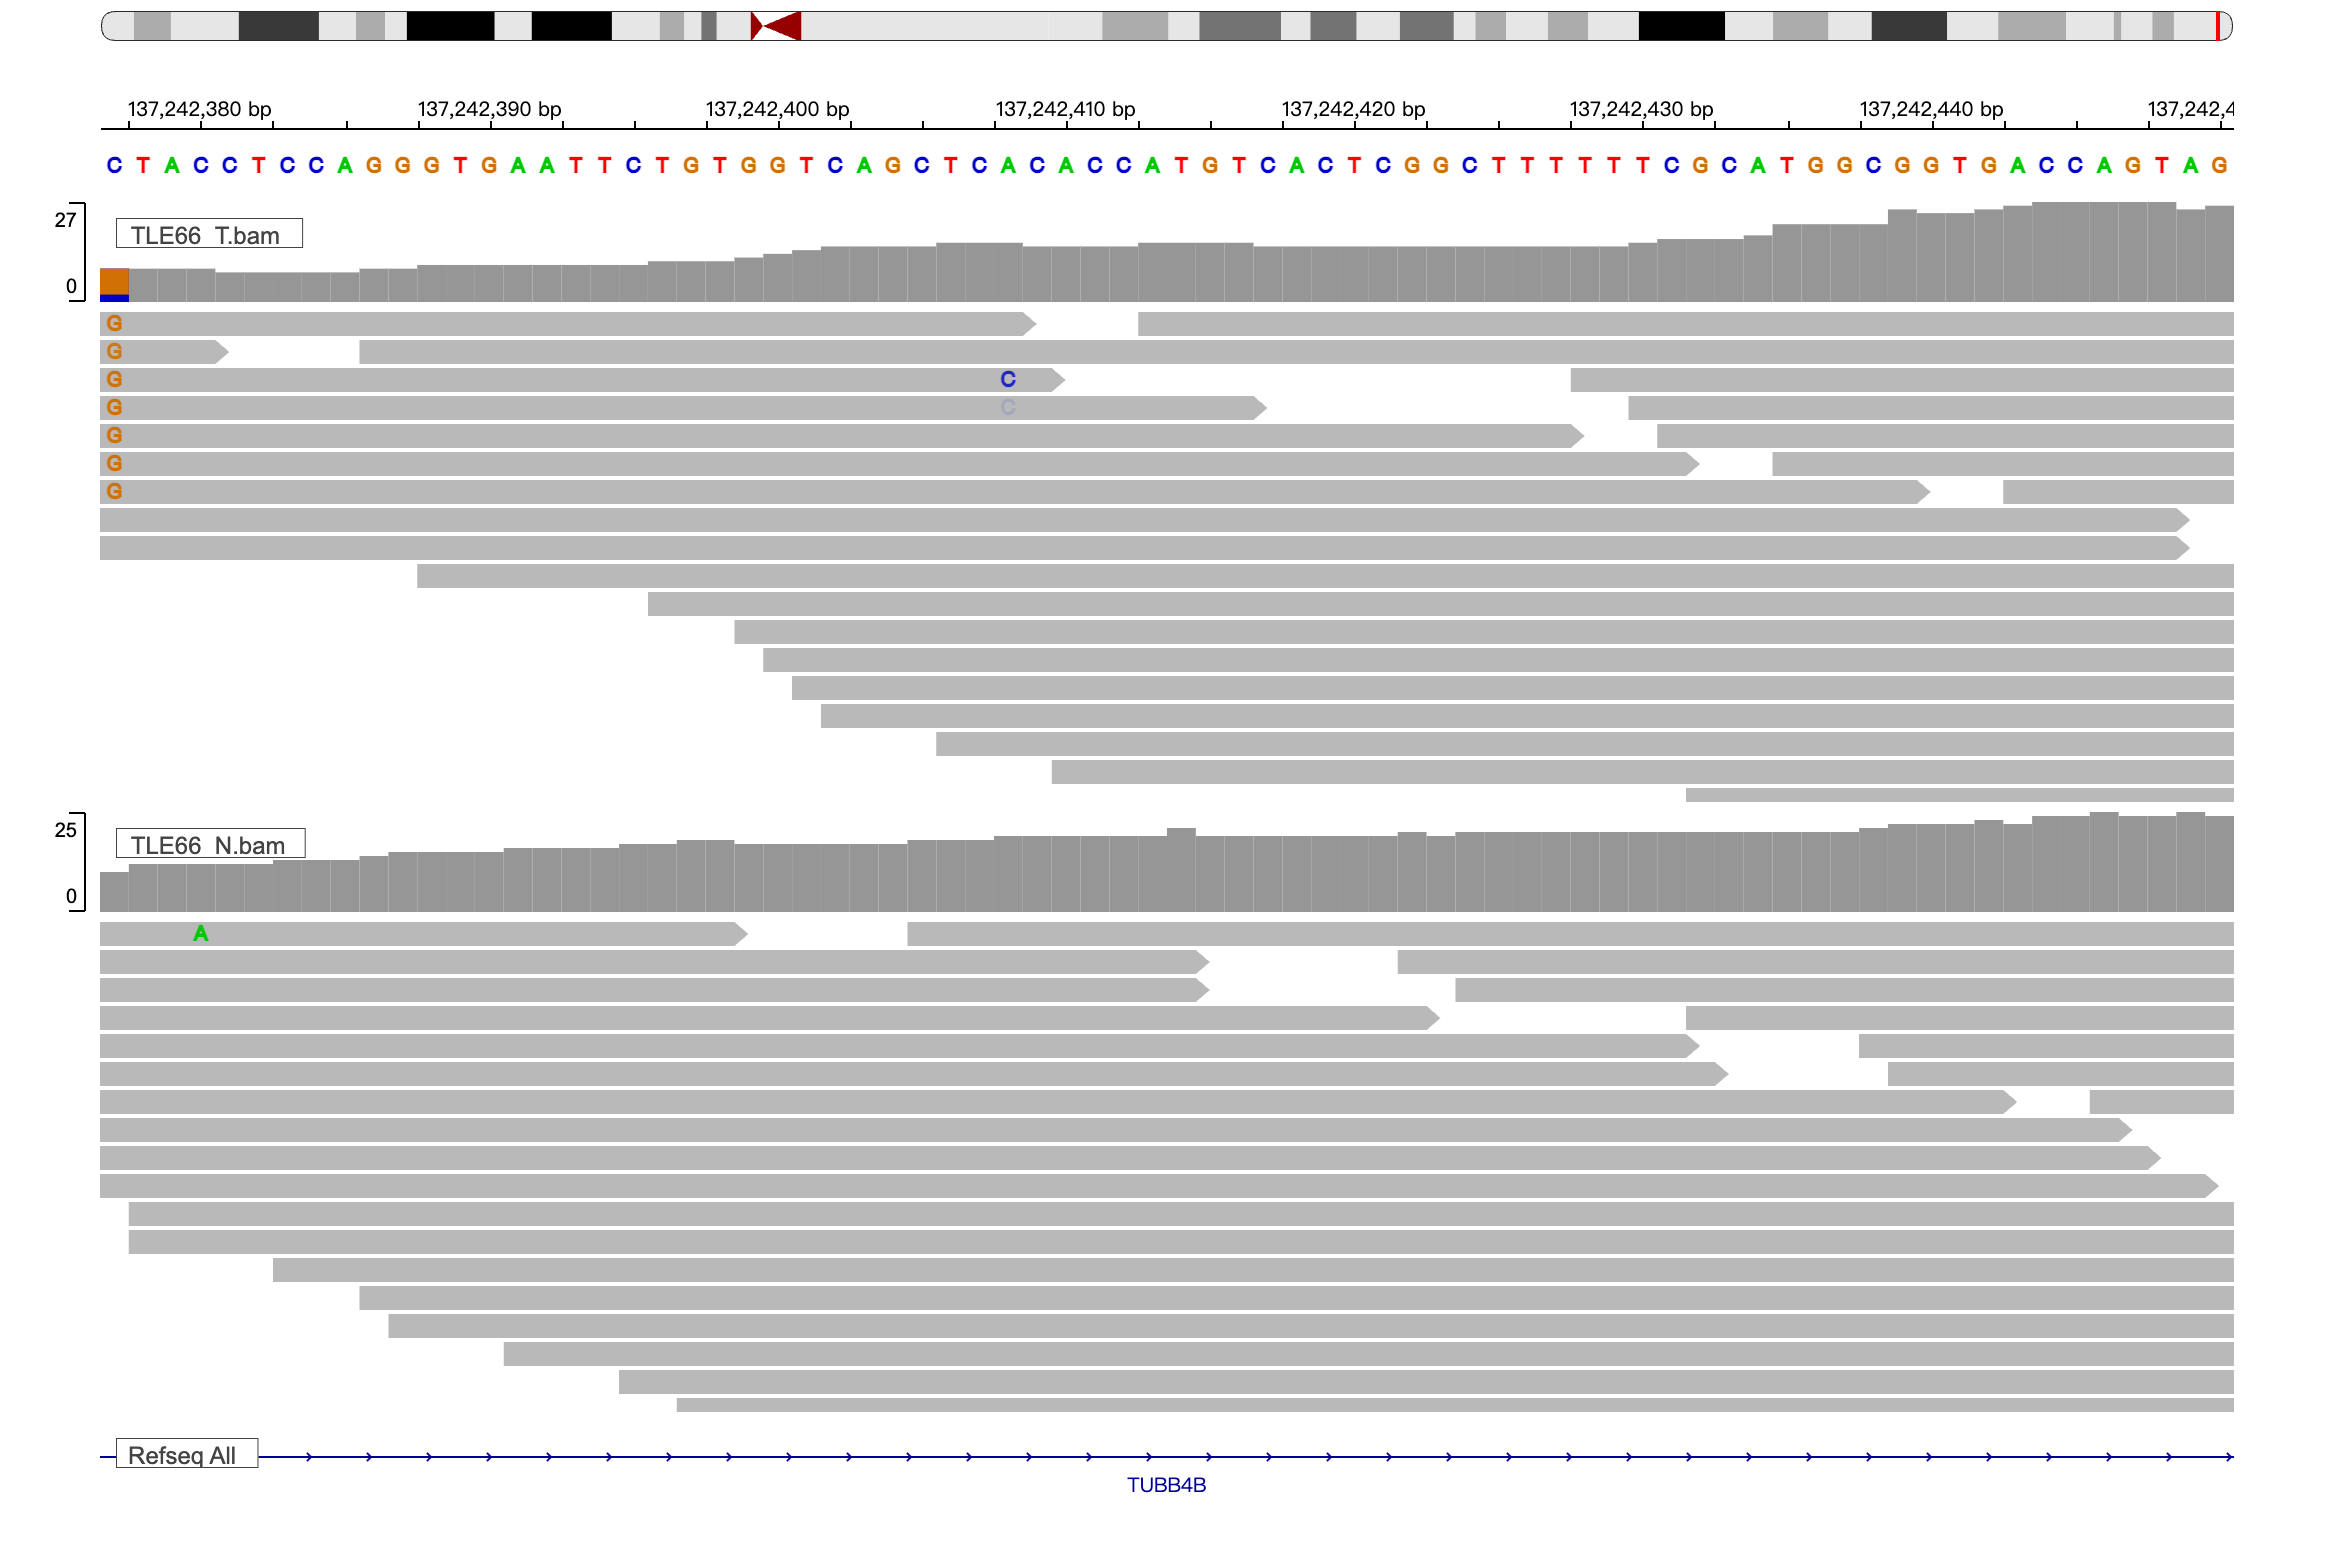
* Visualize the above SNP in IGV, copy/paste a screenshot.
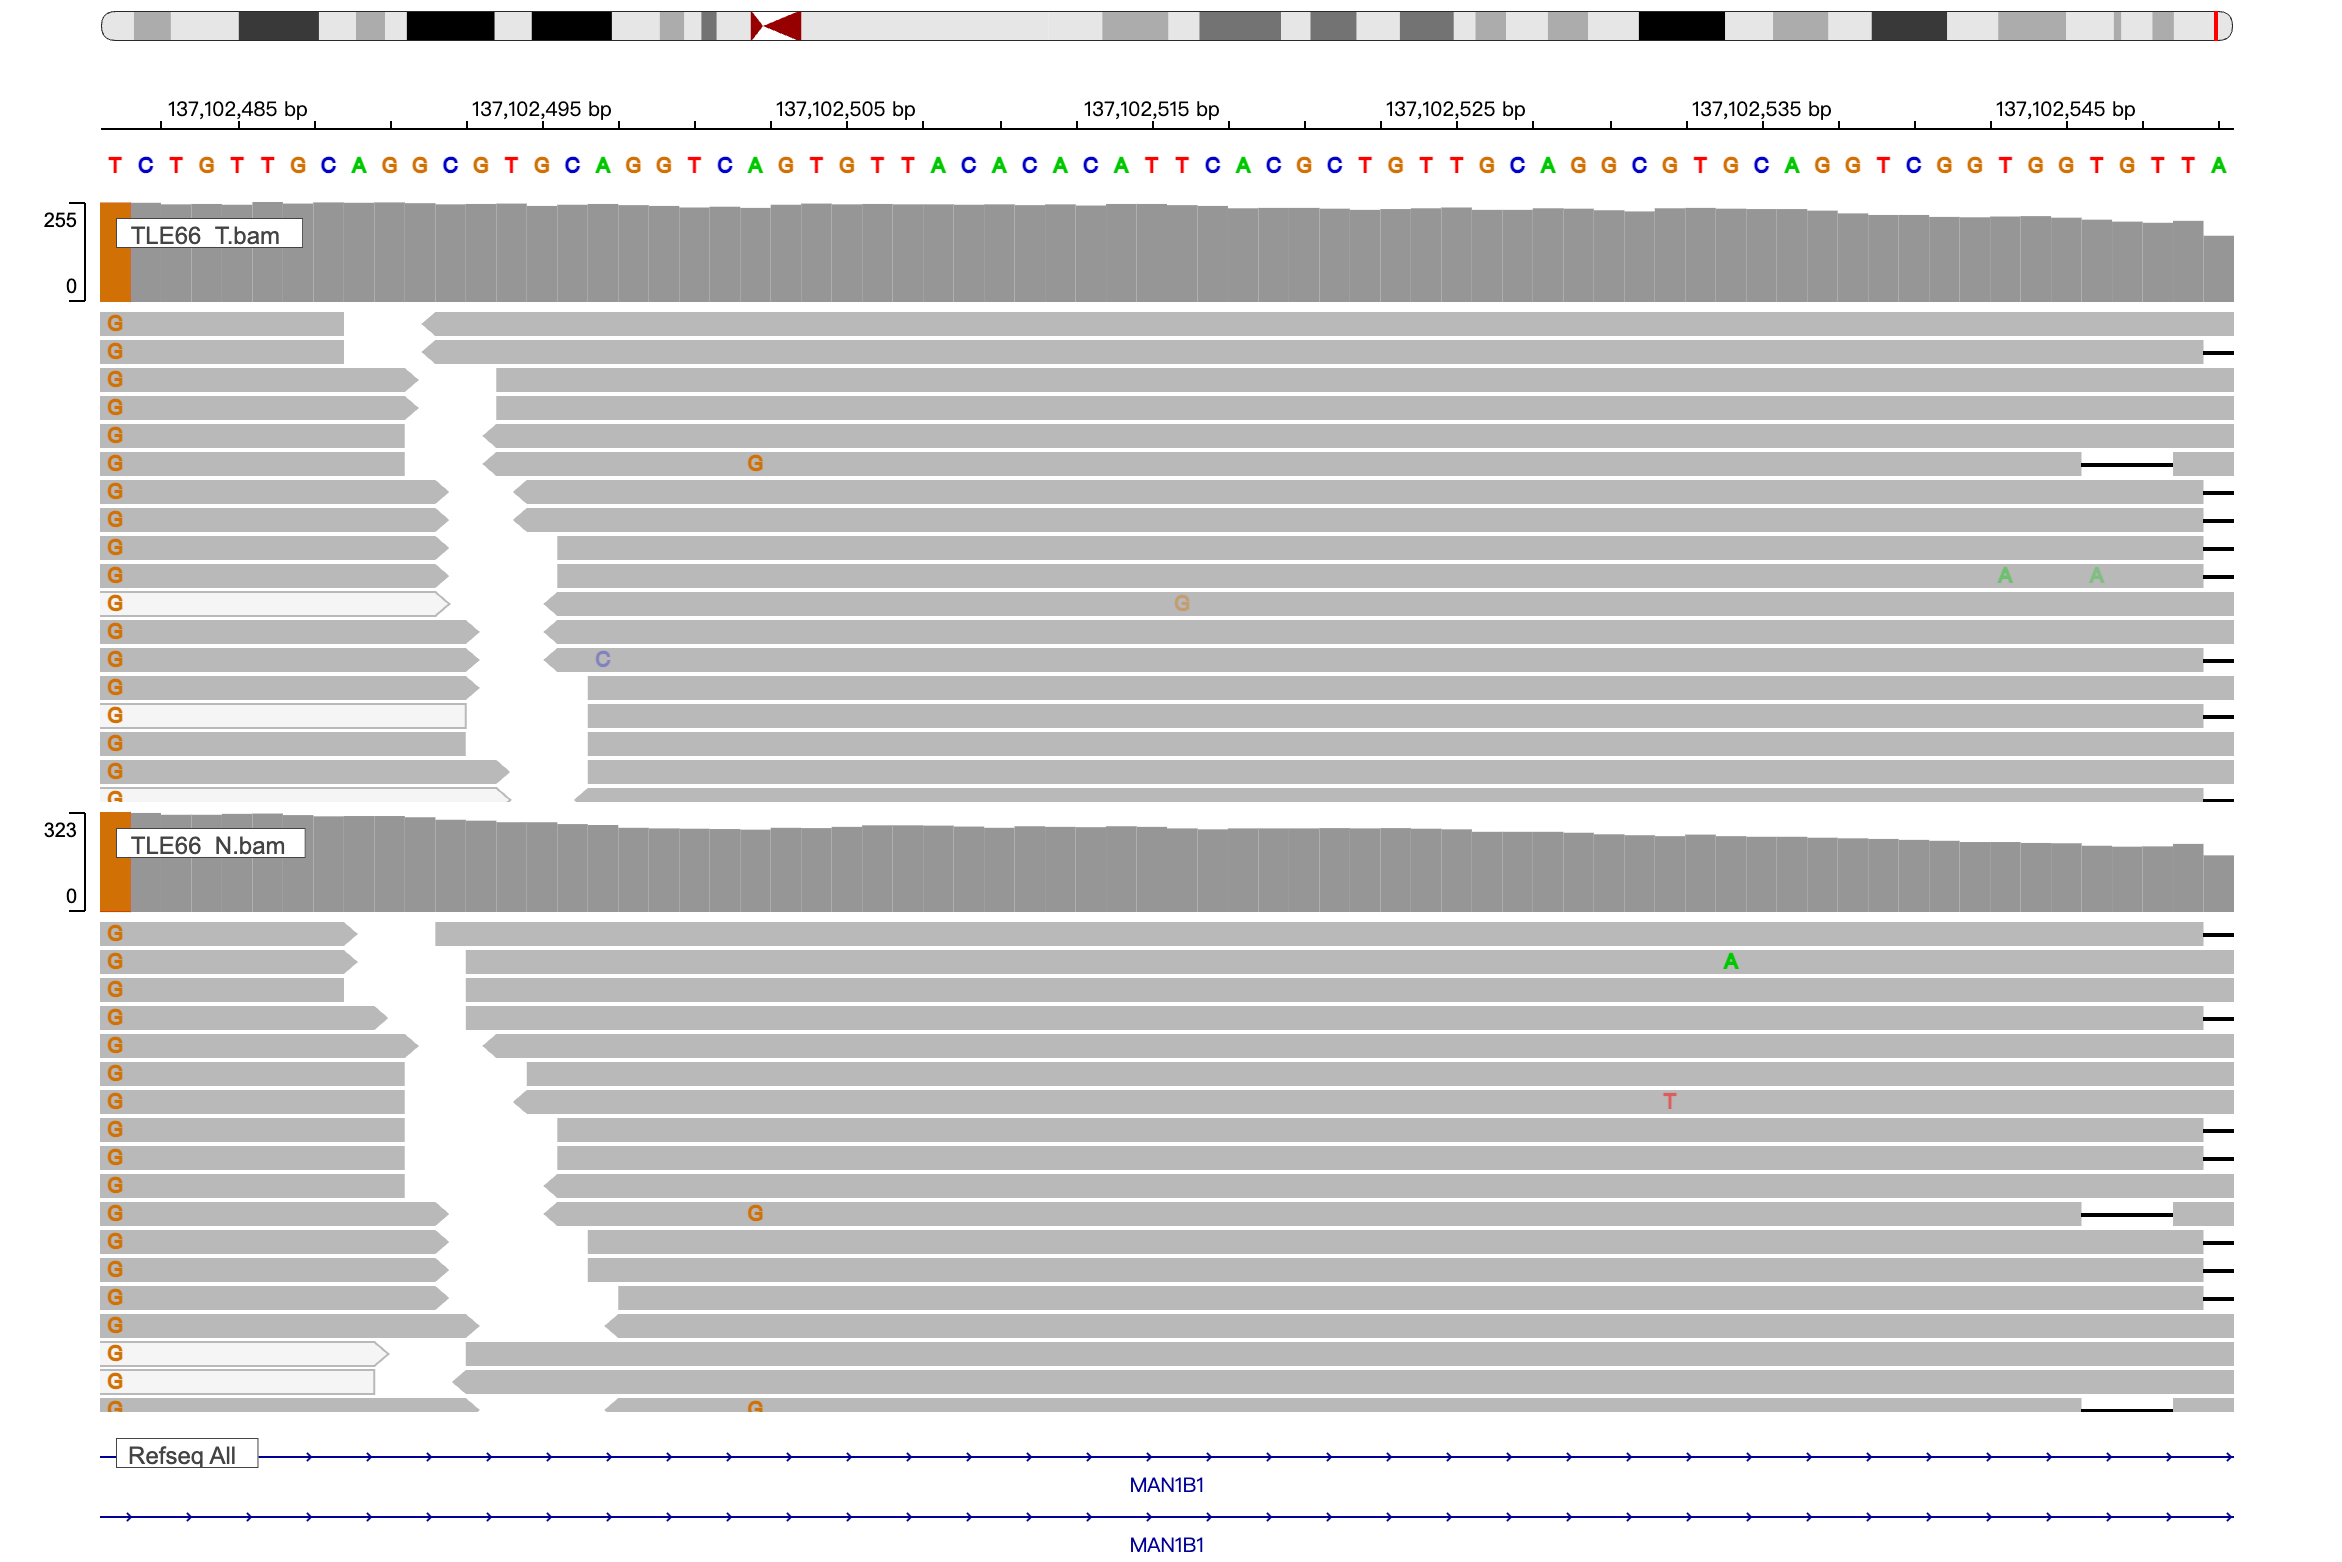
</div>

In [52]:
grep -v '^#' raw_snps.vcf | \
awk 'length($4)==1 && length($5)==1' | \
sort -k6,6nr | head -5

chr9	137102481	.	T	G	486.063	.	DP=471;VDB=0.557019;SGB=-1.38629;RPBZ=1.16838;MQBZ=-1.73258;MQSBZ=0.956502;BQBZ=1.66605;SCBZ=0.147431;MQ0F=0.0636943;AC=4;AN=4;DP4=0,1,243,226;MQ=21	GT:PL:AD	1/1:255,255,0:1,232	1/1:255,255,0:0,236
chr9	128222151	.	C	A	486.059	.	DP=354;VDB=0.214083;SGB=-1.38629;RPBZ=1.30175;MQBZ=0;MQSBZ=0;BQBZ=1.76393;SCBZ=0.0753778;MQ0F=0;AC=4;AN=4;DP4=0,1,298,55;MQ=60	GT:PL:AD	1/1:255,255,0:0,199	1/1:255,255,0:1,154
chr9	138177023	.	C	G	486.057	.	DP=155;VDB=0.694979;SGB=-1.38629;RPBZ=-1.67667;MQBZ=0;MQSBZ=0;BQBZ=1.74177;SCBZ=0;MQ0F=0;AC=4;AN=4;DP4=1,0,119,35;MQ=60	GT:PL:AD	1/1:255,222,0:1,79	1/1:255,226,0:0,75
chr9	128151891	.	C	G	486.051	.	DP=225;VDB=0.378081;SGB=-1.38629;RPBZ=0.854369;MQBZ=0;MQSBZ=0;BQBZ=1.67087;SCBZ=0.0677285;MQ0F=0;AC=4;AN=4;DP4=0,1,153,65;MQ=60	GT:PL:AD	1/1:255,255,0:1,119	1/1:255,255,0:0,99
chr9	133104364	.	C	G	486.048	.	DP=119;VDB=0.7417;SGB=-1.38629;RPBZ=-1.55788;MQBZ=0;MQSBZ=0;BQBZ=1.72619;SCBZ=0.0920575;MQ0F=0;AC=4;AN=4;DP4=1,0,26,92;MQ=60	GT:

In [8]:
grep -v '^#' raw_snps.vcf | \
awk '$6 > 100 && $10 ~ /^0\/0/ && $11 ~ /^[01]\/[01]/ && $11 !~ /^0\/0/' | \
head -10

chr9	137242377	.	C	G	104.473	.	DP=19;VDB=0.311328;SGB=3.31571;RPBZ=1.9041;MQBZ=0;BQBZ=2.55118;SCBZ=0;MQ0F=0;AC=1;AN=4;DP4=12,0,7,0;MQ=60	GT:PL:AD	0/0:0,30,170:10,0	0/1:139,0,35:2,7


In [30]:
grep -v '#' raw_snps.vcf | head -2

chr9	34082802	.	C	T	13.2571	.	DP=2;VDB=0.02;SGB=0.0985265;MQ0F=0;AC=2;AN=2;DP4=0,0,0,2;MQ=22	GT:PL:AD	./.:0,0,0:0,0	1/1:40,6,0:0,2
chr9	34082803	.	A	G	13.2571	.	DP=2;VDB=0.02;SGB=0.0985265;MQ0F=0;AC=2;AN=2;DP4=0,0,0,2;MQ=22	GT:PL:AD	./.:0,0,0:0,0	1/1:40,6,0:0,2


Not all SNPs are equaly convincing

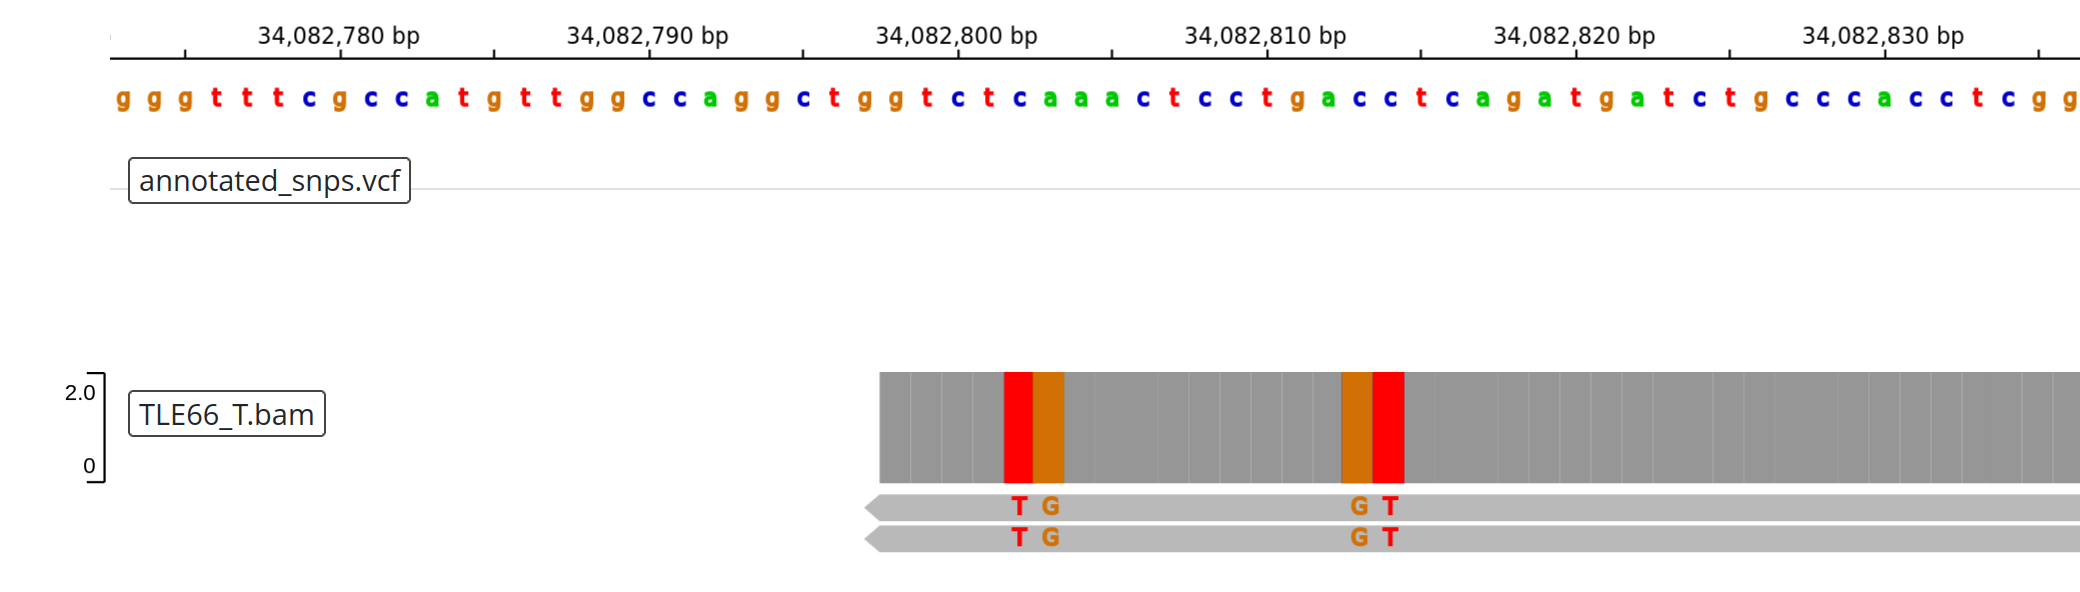

## SNP filtering & cleaning using `vt`

This is a VCF preprocessing pipeline that cleans up raw SNP calls before any downstream analysis. Each step fixes a specific class of problem:

* `vt decompose` splits multi-allelic variants (where multiple alternate alleles are listed on a single line) into separate biallelic records. Most tools downstream expect one variant per line, and PRS methods in particular are built around biallelic SNPs.
* `vt normalize -n -r $DB` left-aligns and normalizes indels against the reference genome. The same variant can be represented in multiple valid ways in VCF format — normalization ensures you have one canonical representation, which is critical when matching variants across datasets (e.g., GWAS summary statistics vs. your genotype calls).
* `vt uniq` removes exact duplicate records that may have arisen after decomposition and normalization — two originally different representations that are now identical.
* `vt view -f "QUAL>20"` filters out low-confidence variant calls. QUAL<20 corresponds roughly to less than 99% confidence that the variant is real, so you're dropping the noisiest calls.


In [31]:
cat raw_snps.vcf \
    | vt decompose - \
    | vt normalize -n -r $DB - \
    | vt uniq - \
    | vt view -f "QUAL>20" -h - \
    > clean_snps.vcf

uniq v0.57

options:     input VCF file        -
         [o] output VCF file       -
normalize v0.5

options:     input VCF file                                  -
         [o] output VCF file                                 -
         [w] sorting window size                             10000
         [n] no fail on reference inconsistency for non SNPs true
         [q] quiet                                           false
         [d] debug                                           false
         [r] reference FASTA file                            /staging/leuven/stg_00079/teaching/hg38_9/chr9.fa

decompose v0.5

options:     input VCF file        -
         [s] smart decomposition   false (experimental)
         [o] output VCF file       -


stats: no. variants                 : 6661
       no. biallelic variants       : 6659
       no. multiallelic variants    : 2

       no. additional biallelics    : 2
       total no. of biallelics      : 6663

Time elapsed: 0.02s


stats: biall


<div style="background-color: khaki; padding: 10px;">

## Quality control

* Did all tools finish without error?
* Yes
* Is the file structure correct? (no lines, start, end, header, etc)
* Yes, codes are as follows,checking for lines, start, end and header
* Find a high quality SNP (awk, sort, excel, whatever you like). Discuss the criteria.
* chr9:137102481 T>G.The criteria is the high quality with the high coverage depth. codes are as follows.
* Attempt to find a variants that are different between the two samples (awk?). Check in IGV, copy/paste screenshot.
* 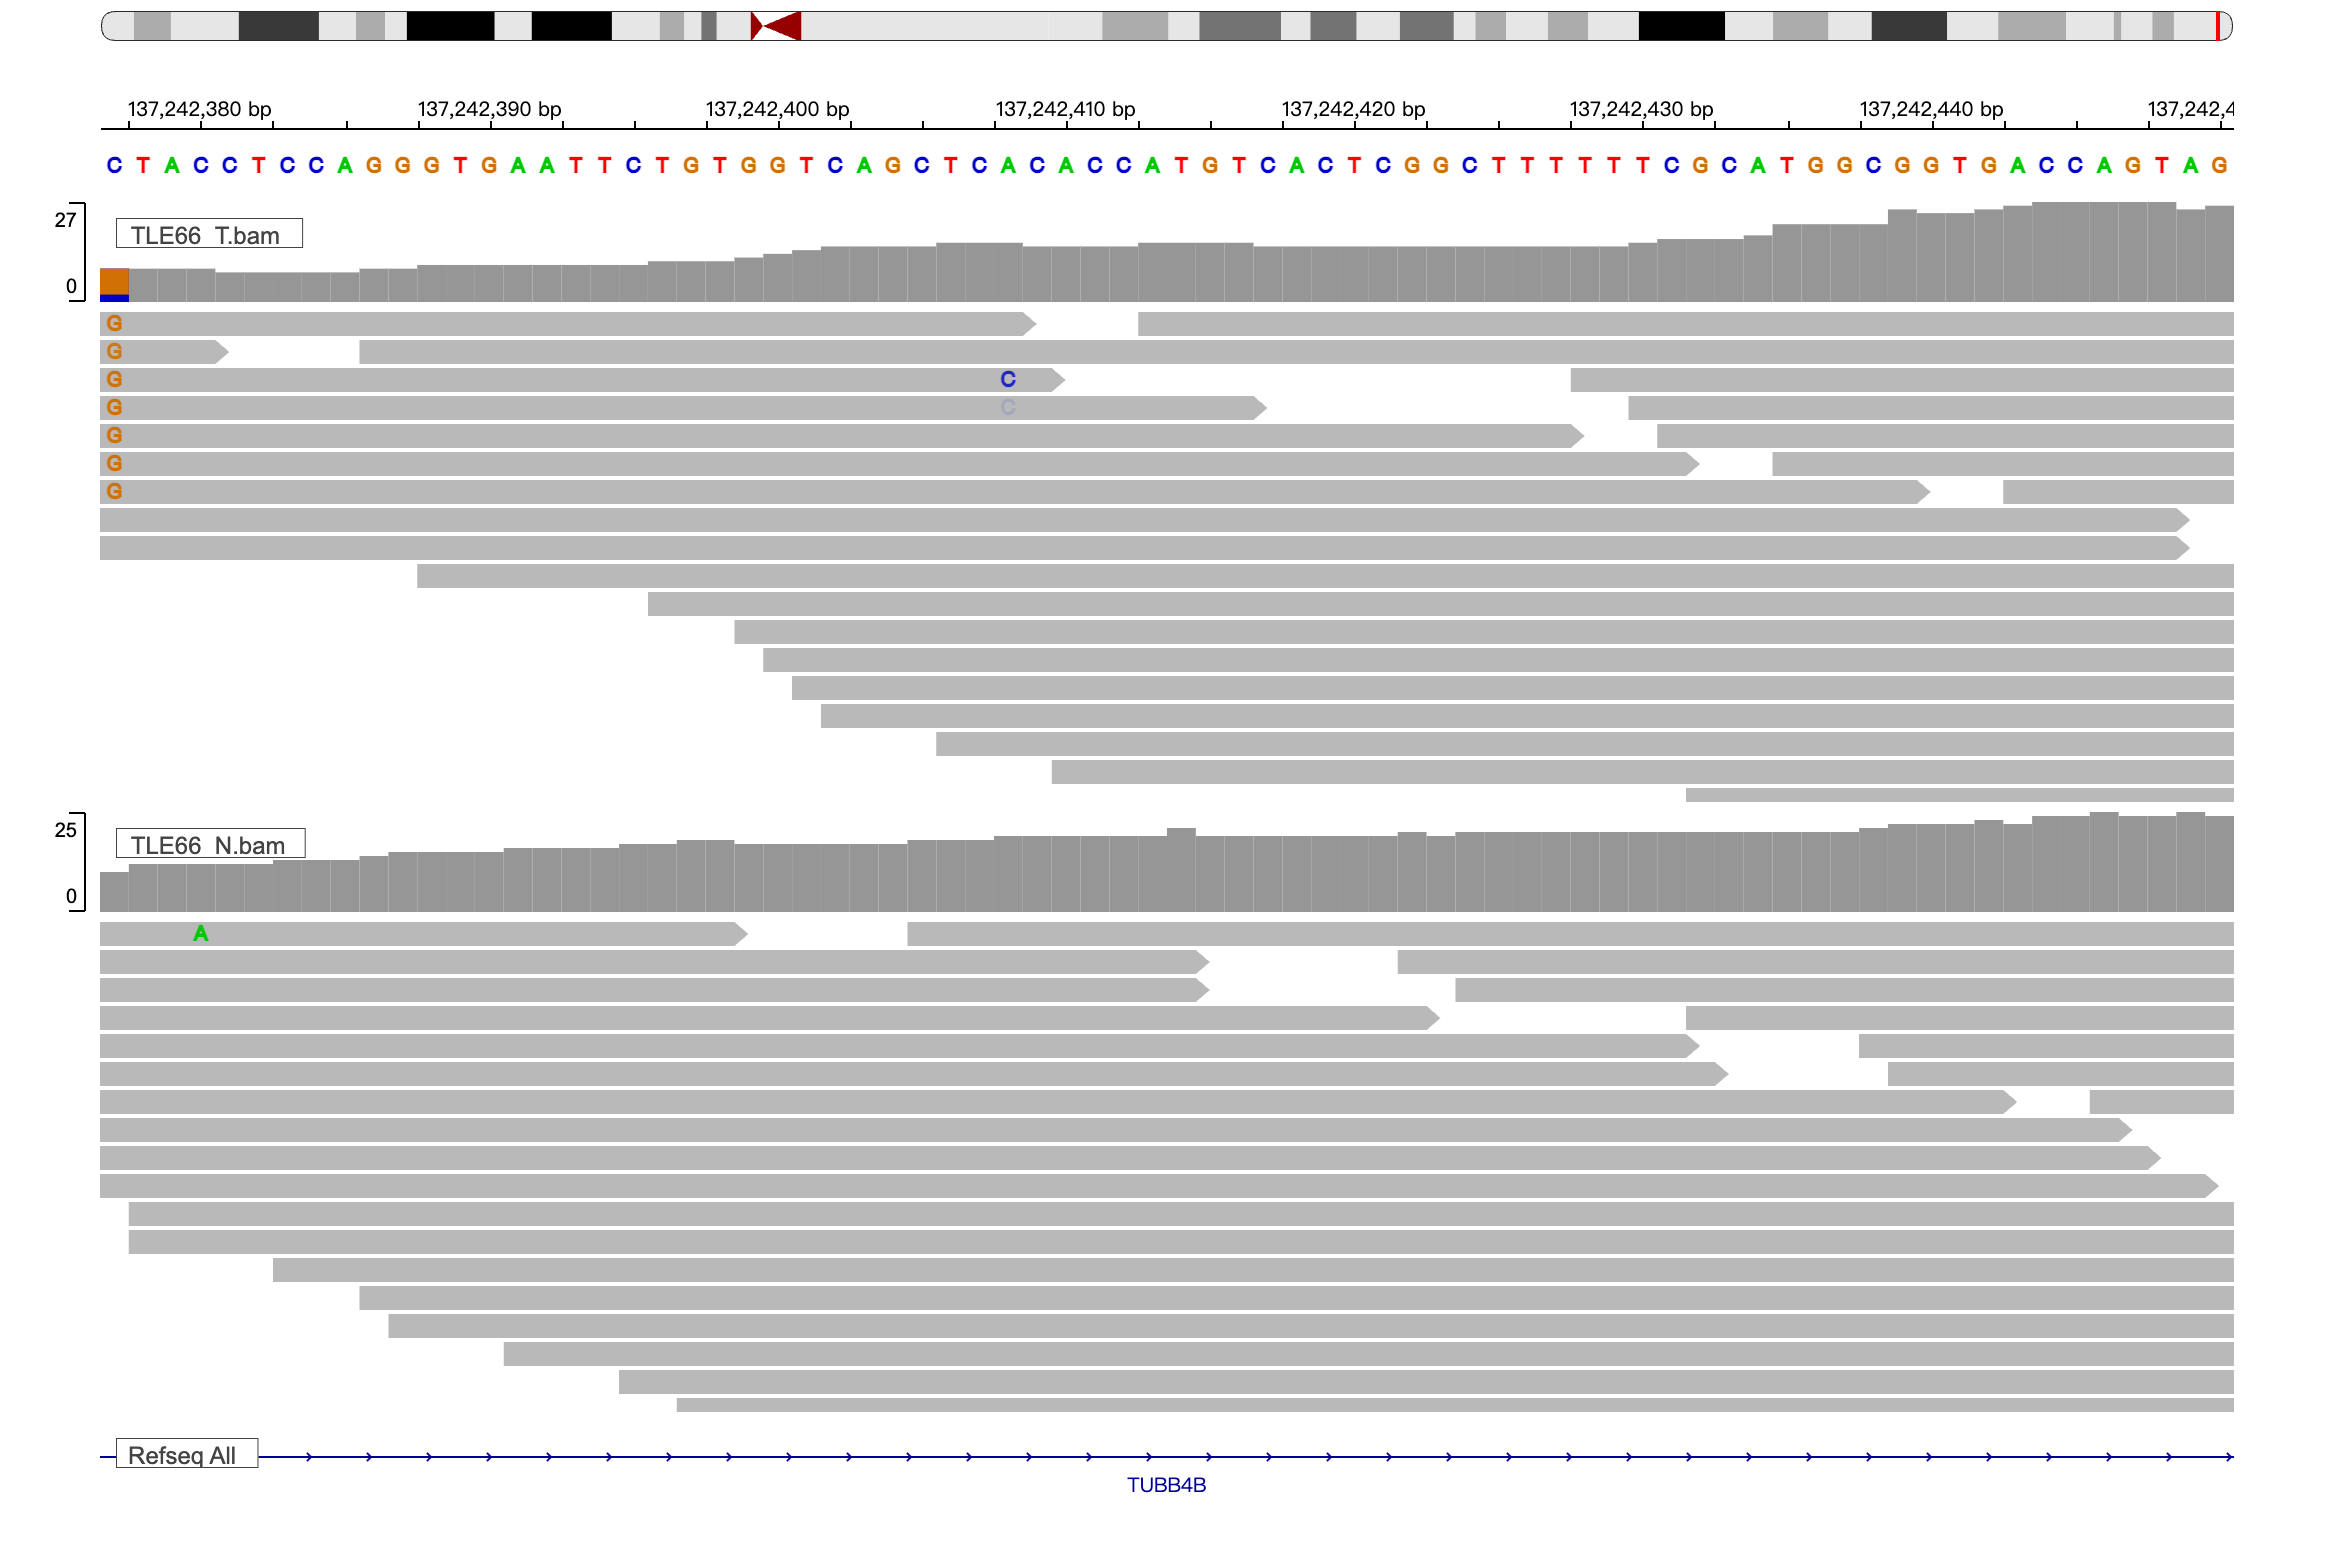
* Visualize the above SNP in IGV, copy/paste a screenshot.
* 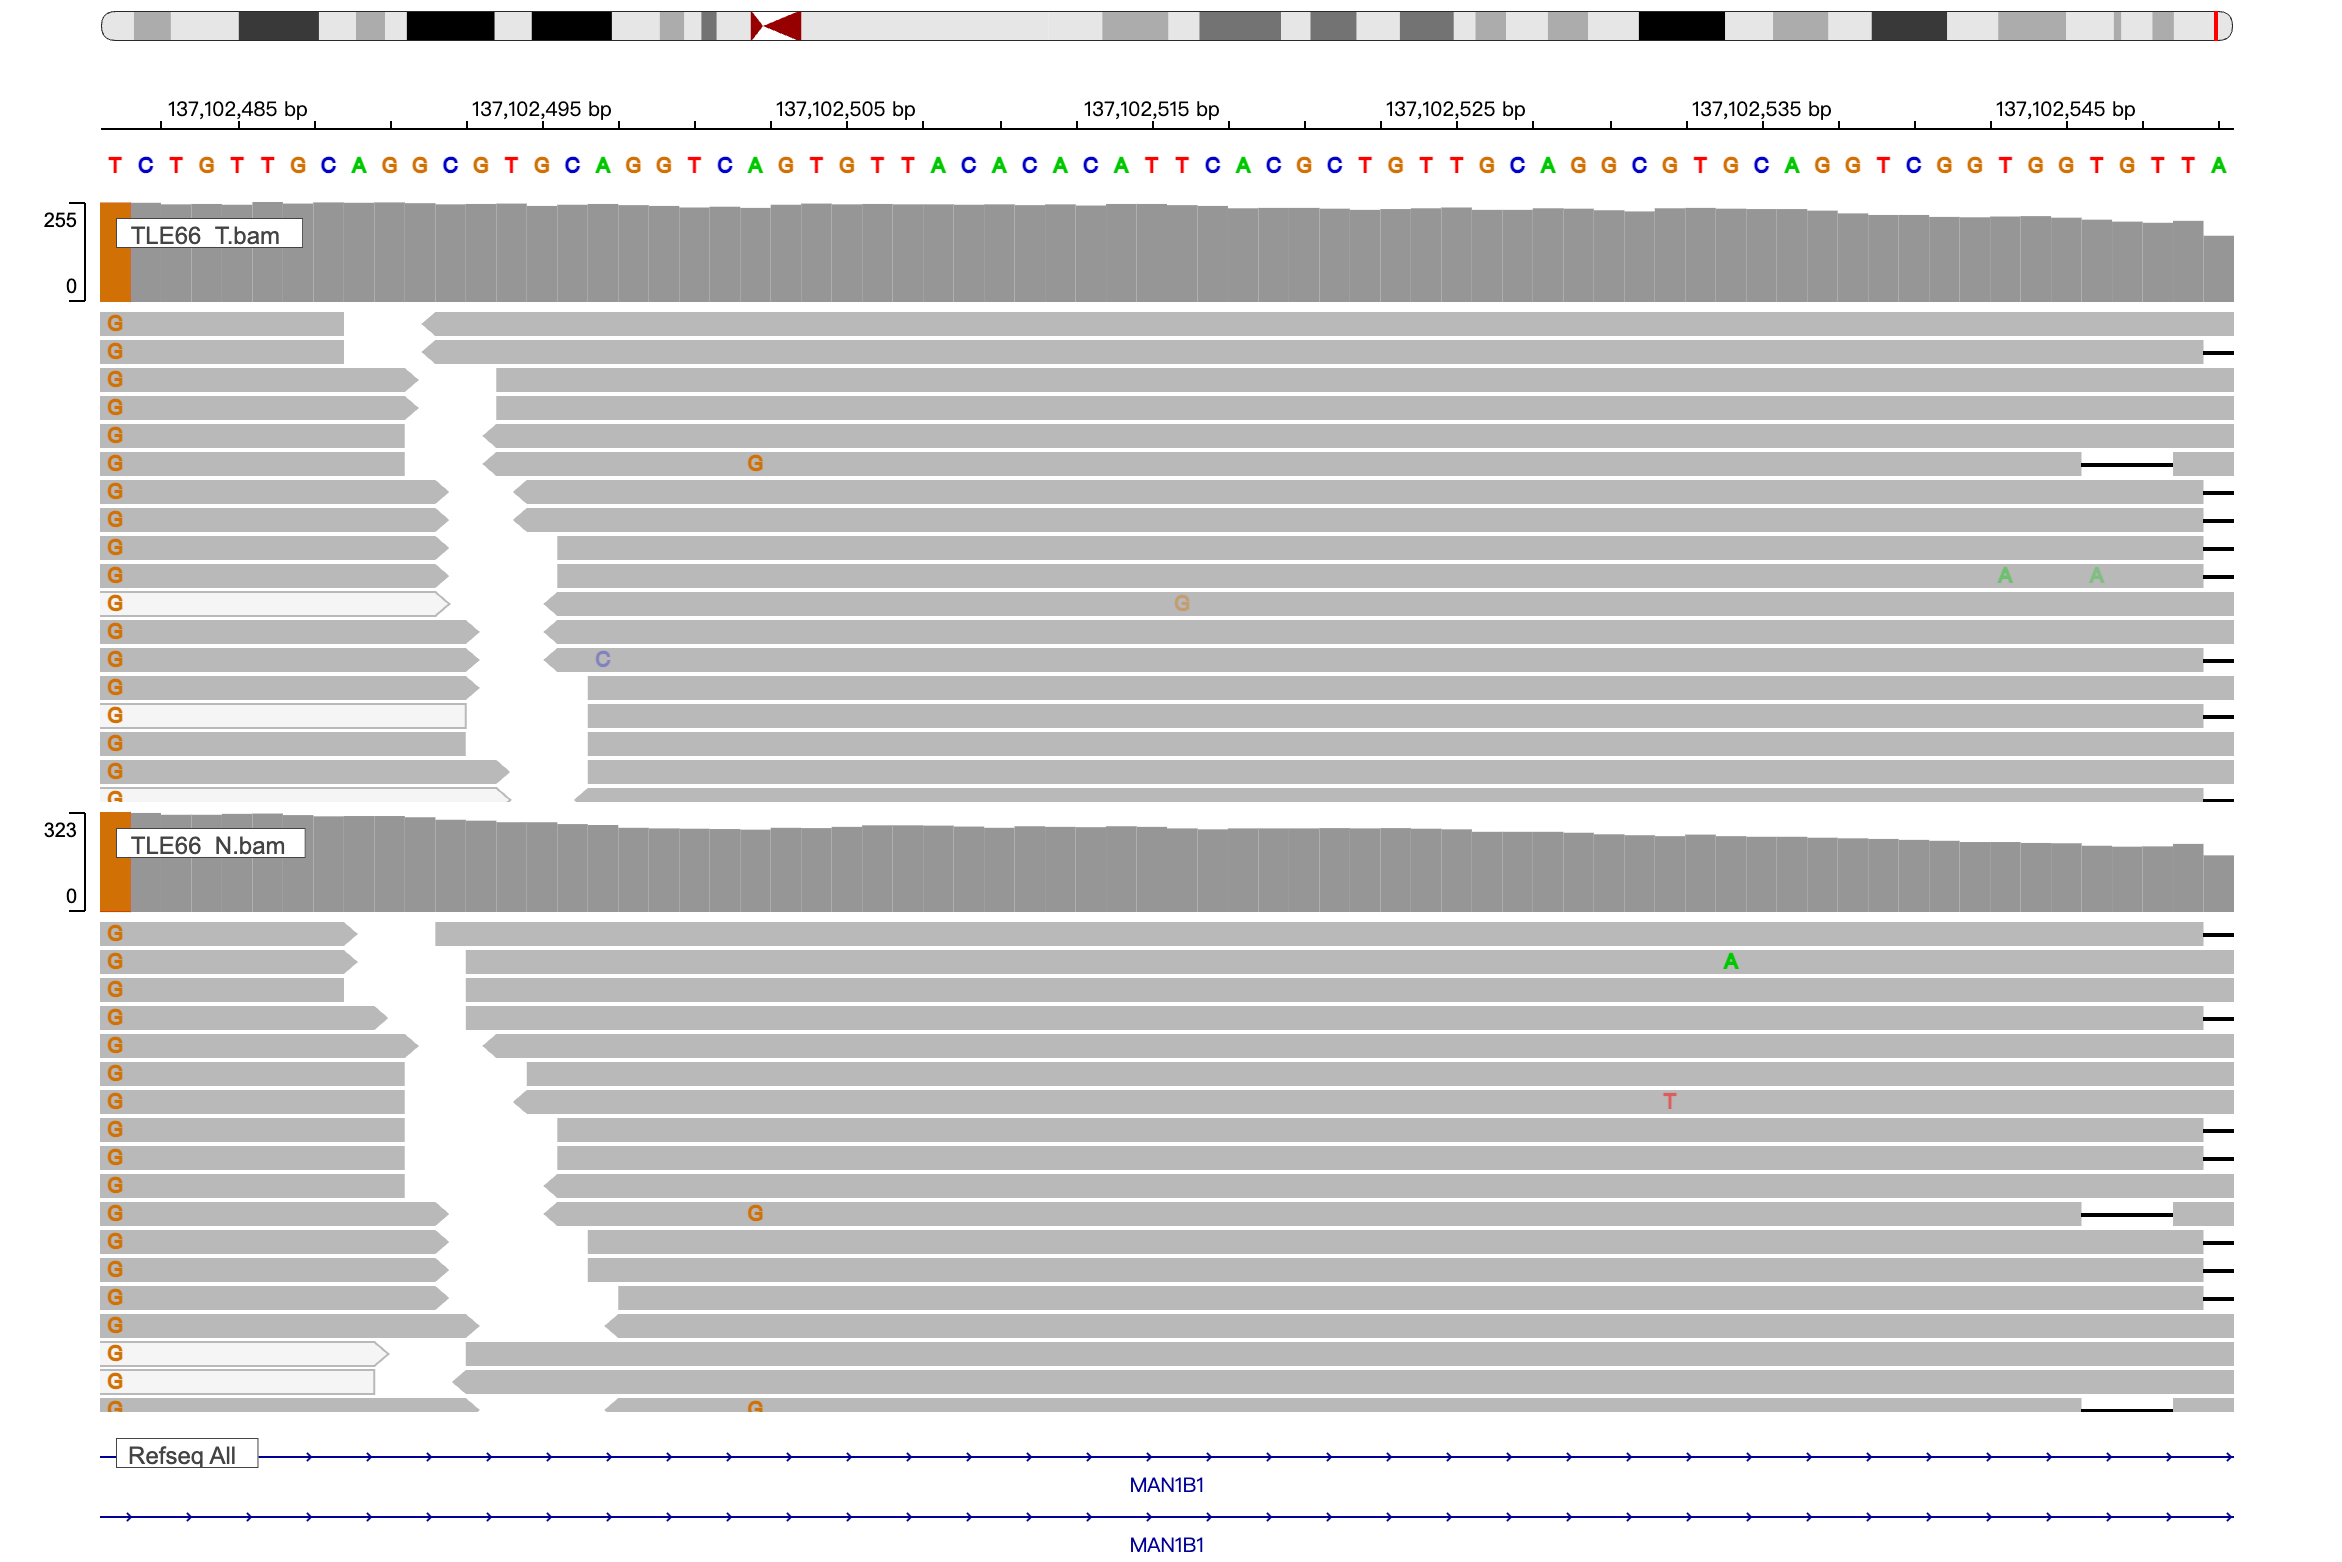

</div>



In [9]:
head -5 clean_snps.vcf

##fileformat=VCFv4.2
##FILTER=<ID=PASS,Description="All filters passed">
##bcftoolsVersion=1.23+htslib-1.23
##bcftoolsCommand=mpileup -Ou -f /staging/leuven/stg_00079/teaching/hg38_9/chr9.fa TLE66_N.bam TLE66_T.bam
##reference=file:///staging/leuven/stg_00079/teaching/hg38_9/chr9.fa


In [11]:
grep '^#CHROM' clean_snps.vcf

#CHROM	POS	ID	REF	ALT	QUAL	FILTER	INFO	FORMAT	TLE66_N.bam	TLE66_T.bam


In [12]:
echo "total lines: $(wc -l < clean_snps.vcf)"
echo "header lines: $(grep -c '^#' clean_snps.vcf)"
echo "data lines: $(grep -c -v '^#' clean_snps.vcf)"

total lines: 3530
header lines: 31
data lines: 3499


In [10]:
tail -3 clean_snps.vcf

chr9	138243732	.	A	G	145.826	.	DP=29;VDB=0.683888;SGB=-4.72235;RPBZ=-0.235789;MQBZ=0;MQSBZ=0;BQBZ=-0.316431;SCBZ=0.590389;MQ0F=0;AC=2;AN=4;DP4=5,15,1,8;MQ=60	GT:PL:AD	0/1:91,0,174:8,5	0/1:89,0,222:12,4
chr9	138249280	.	G	C	125.856	.	DP=24;VDB=0.0967644;SGB=-4.10598;RPBZ=2.92979;MQBZ=0;BQBZ=3.8343;SCBZ=0;MQ0F=0;AC=2;AN=4;DP4=17,0,7,0;MQ=60	GT:PL:AD	0/1:106,0,58:3,4	0/1:53,0,119:14,3
chr9	138249462	.	C	T	23.1397	.	DP=7;VDB=0.32;SGB=0.00473136;RPBZ=0.387298;MQBZ=0;BQBZ=1.97203;SCBZ=0;MQ0F=0;AC=1;AN=4;DP4=0,5,0,2;MQ=60	GT:PL:AD	0/0:0,12,85:4,0	0/1:57,0,19:1,2


In [13]:
grep -v '^#' clean_snps.vcf | \
awk 'length($4)==1 && length($5)==1' | \
sort -k6,6nr | head -5

chr9	137102481	.	T	G	486.063	.	DP=471;VDB=0.557019;SGB=-1.38629;RPBZ=1.16838;MQBZ=-1.73258;MQSBZ=0.956502;BQBZ=1.66605;SCBZ=0.147431;MQ0F=0.0636943;AC=4;AN=4;DP4=0,1,243,226;MQ=21	GT:PL:AD	1/1:255,255,0:1,232	1/1:255,255,0:0,236
chr9	128222151	.	C	A	486.059	.	DP=354;VDB=0.214083;SGB=-1.38629;RPBZ=1.30175;MQBZ=0;MQSBZ=0;BQBZ=1.76393;SCBZ=0.0753778;MQ0F=0;AC=4;AN=4;DP4=0,1,298,55;MQ=60	GT:PL:AD	1/1:255,255,0:0,199	1/1:255,255,0:1,154
chr9	138177023	.	C	G	486.057	.	DP=155;VDB=0.694979;SGB=-1.38629;RPBZ=-1.67667;MQBZ=0;MQSBZ=0;BQBZ=1.74177;SCBZ=0;MQ0F=0;AC=4;AN=4;DP4=1,0,119,35;MQ=60	GT:PL:AD	1/1:255,222,0:1,79	1/1:255,226,0:0,75
chr9	128151891	.	C	G	486.051	.	DP=225;VDB=0.378081;SGB=-1.38629;RPBZ=0.854369;MQBZ=0;MQSBZ=0;BQBZ=1.67087;SCBZ=0.0677285;MQ0F=0;AC=4;AN=4;DP4=0,1,153,65;MQ=60	GT:PL:AD	1/1:255,255,0:1,119	1/1:255,255,0:0,99
chr9	133104364	.	C	G	486.048	.	DP=119;VDB=0.7417;SGB=-1.38629;RPBZ=-1.55788;MQBZ=0;MQSBZ=0;BQBZ=1.72619;SCBZ=0.0920575;MQ0F=0;AC=4;AN=4;DP4=1,0,26,92;MQ=60	GT:

In [14]:
grep -v '^#' clean_snps.vcf | \
awk '$6 > 100 && $10 ~ /^0\/0/ && $11 ~ /^[01]\/[01]/ && $11 !~ /^0\/0/' | \
head -5 | cut -f1-5,10-11

chr9	137242377	.	C	G	0/0:0,30,170:10,0	0/1:139,0,35:2,7


## Snp Annotation using SnpEff

In [32]:
# get help using:
snpEff || true

Error        :	Missing genomer_version parameter
Command line :	SnpEff  

snpEff version SnpEff 5.4a (build 2025-11-25 12:22), by Pablo Cingolani
Usage: snpEff [ann] [options] genome_version [input_file]


	variants_file                   : Default is STDIN



Options:
	-chr <string>                   : Prepend 'string' to chromosome name (e.g. 'chr1' instead of '1'). Only on TXT output.
	-classic                        : Use old style annotations instead of Sequence Ontology and Hgvs.
	-csvStats <file>                : Create CSV summary file.
	-download                       : Download reference genome if not available. Default: true
	-i <format>                     : Input format [ vcf, bed ]. Default: VCF.
	-fileList                       : Input actually contains a list of files to process.
	-o <format>                     : Output format [ vcf, gatk, bed, bedAnn ]. Default: VCF.
	-s , -stats, -htmlStats         : Create HTML summary file.  Default is 'snpEff_summary.html'
	-noSta

In [33]:
# sorry this is ugly - but to run snpEff - we need more memory
# I'm sure there is a more elegant way - but I could not find it..

SNPEFF_JAR="/lustre1/project/stg_00079/teaching/I0U19a_conda_2026/share/snpeff-5.4.0a-0/snpEff.jar"

java -Xmx3400m -jar ${SNPEFF_JAR} eff hg19 -dataDir /staging/leuven/stg_00079/teaching/snpeff_db \
        clean_snps.vcf > annotated_snps.vcf



NEW VERSION!
	There is a new SnpEff version available: 
		Version      : 5.4C
		Release date : 2026-02-23
		Download URL : https://snpeff-public.s3.amazonaws.com/versions/snpEff_latest_core.zip



<div style="background-color: khaki; padding: 10px;">

## snpEff Quality control

* Do you have annotations in the records? Show one HIGH impact one?
* Yes, as follows.
* Can you think of other (simple) controls for a snpEff annotated vcf file?
* There is a problem about this annotated file. While hg19 was used as the reference to do the annotation, h38 was used as the reference sequence for all above files except for this one. Thus, when we use annotated_snps.vcf to align h38 reference, we get the gene name MAN1B1 for this location (137102481), but  we get different gene name(maybe RNU6ATAC-LINC02247)，which appears in the annotation. As you can see the picture below.
* 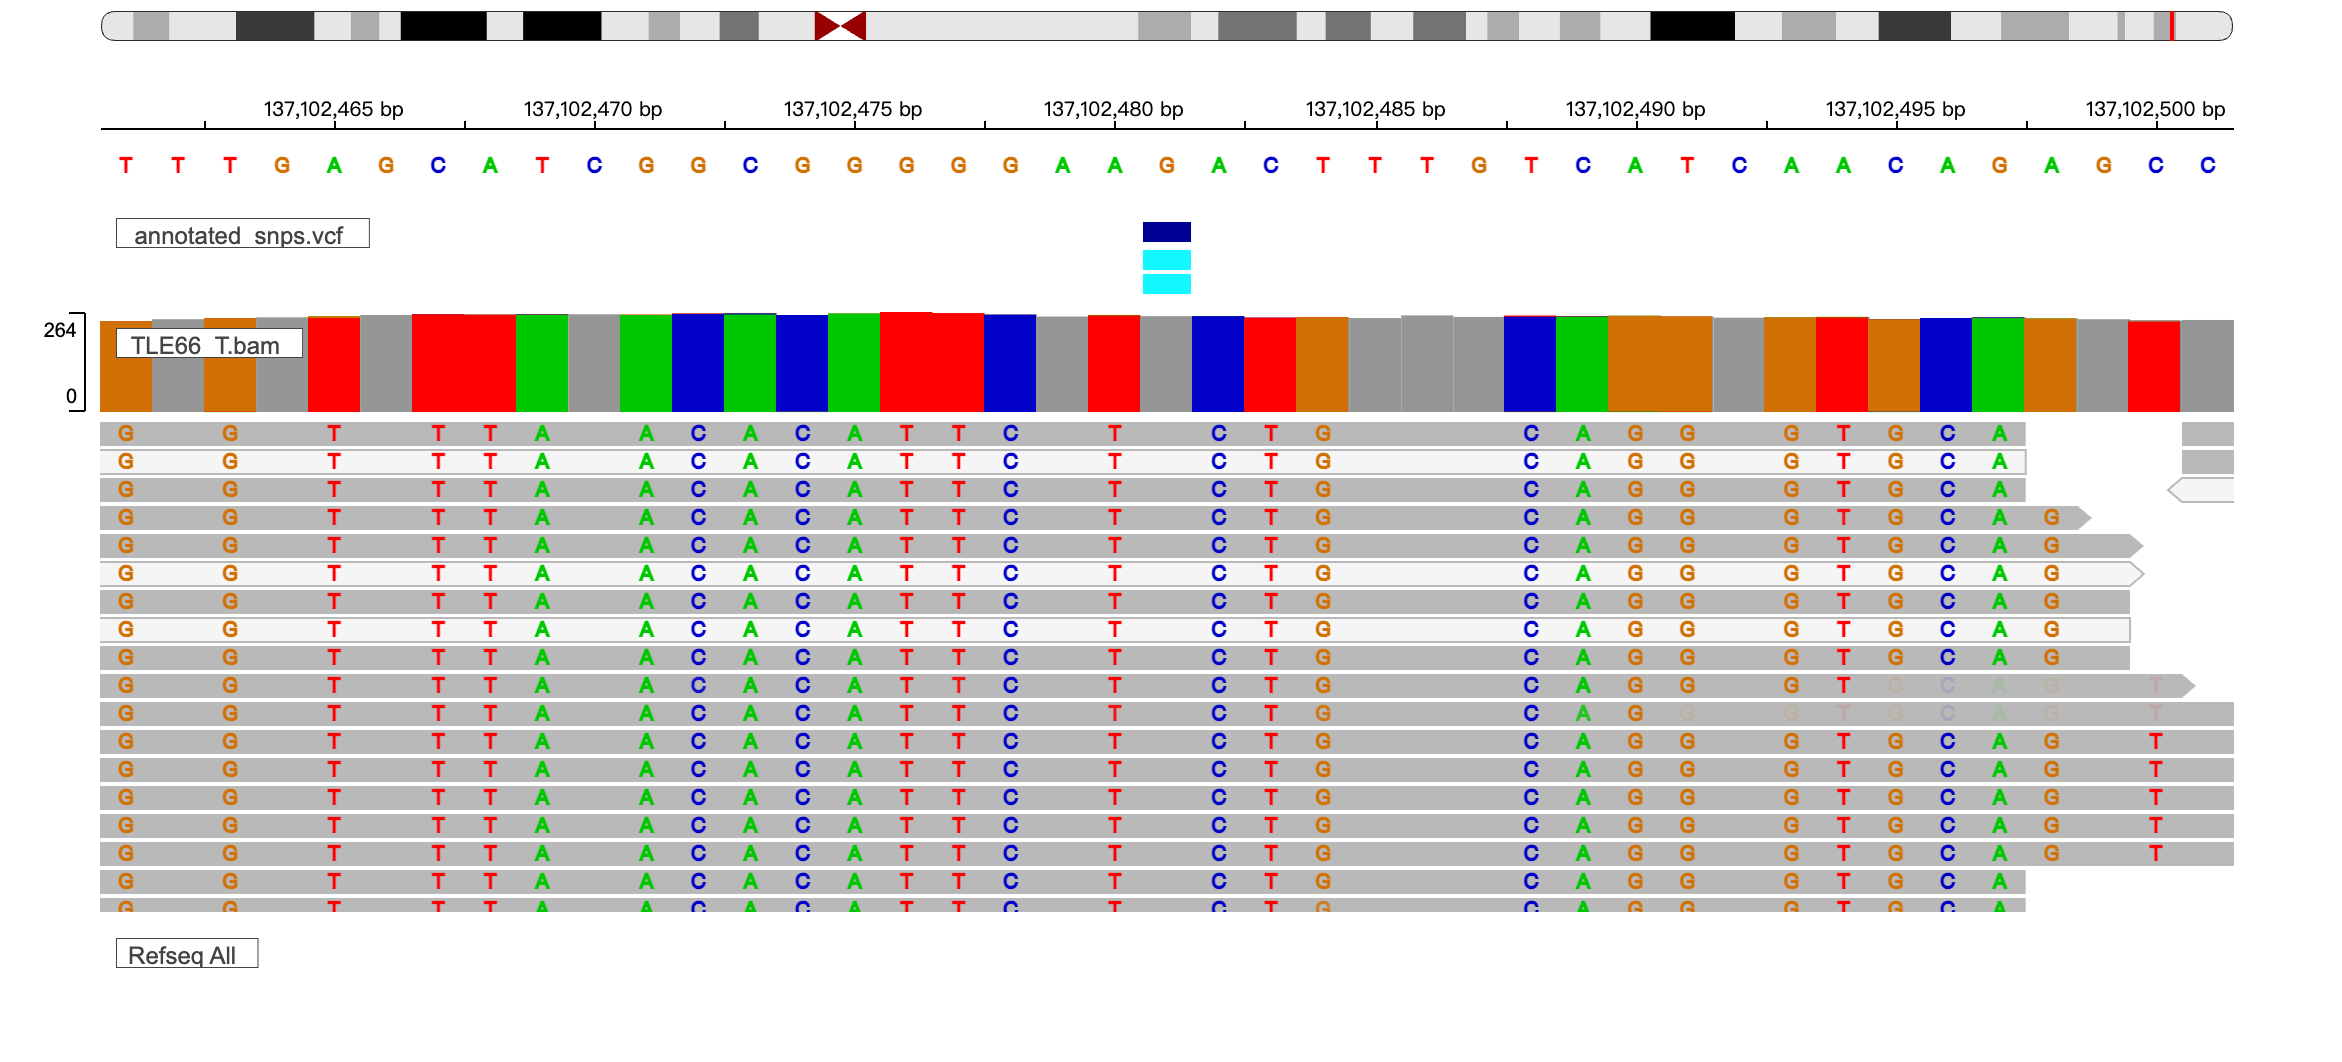
* 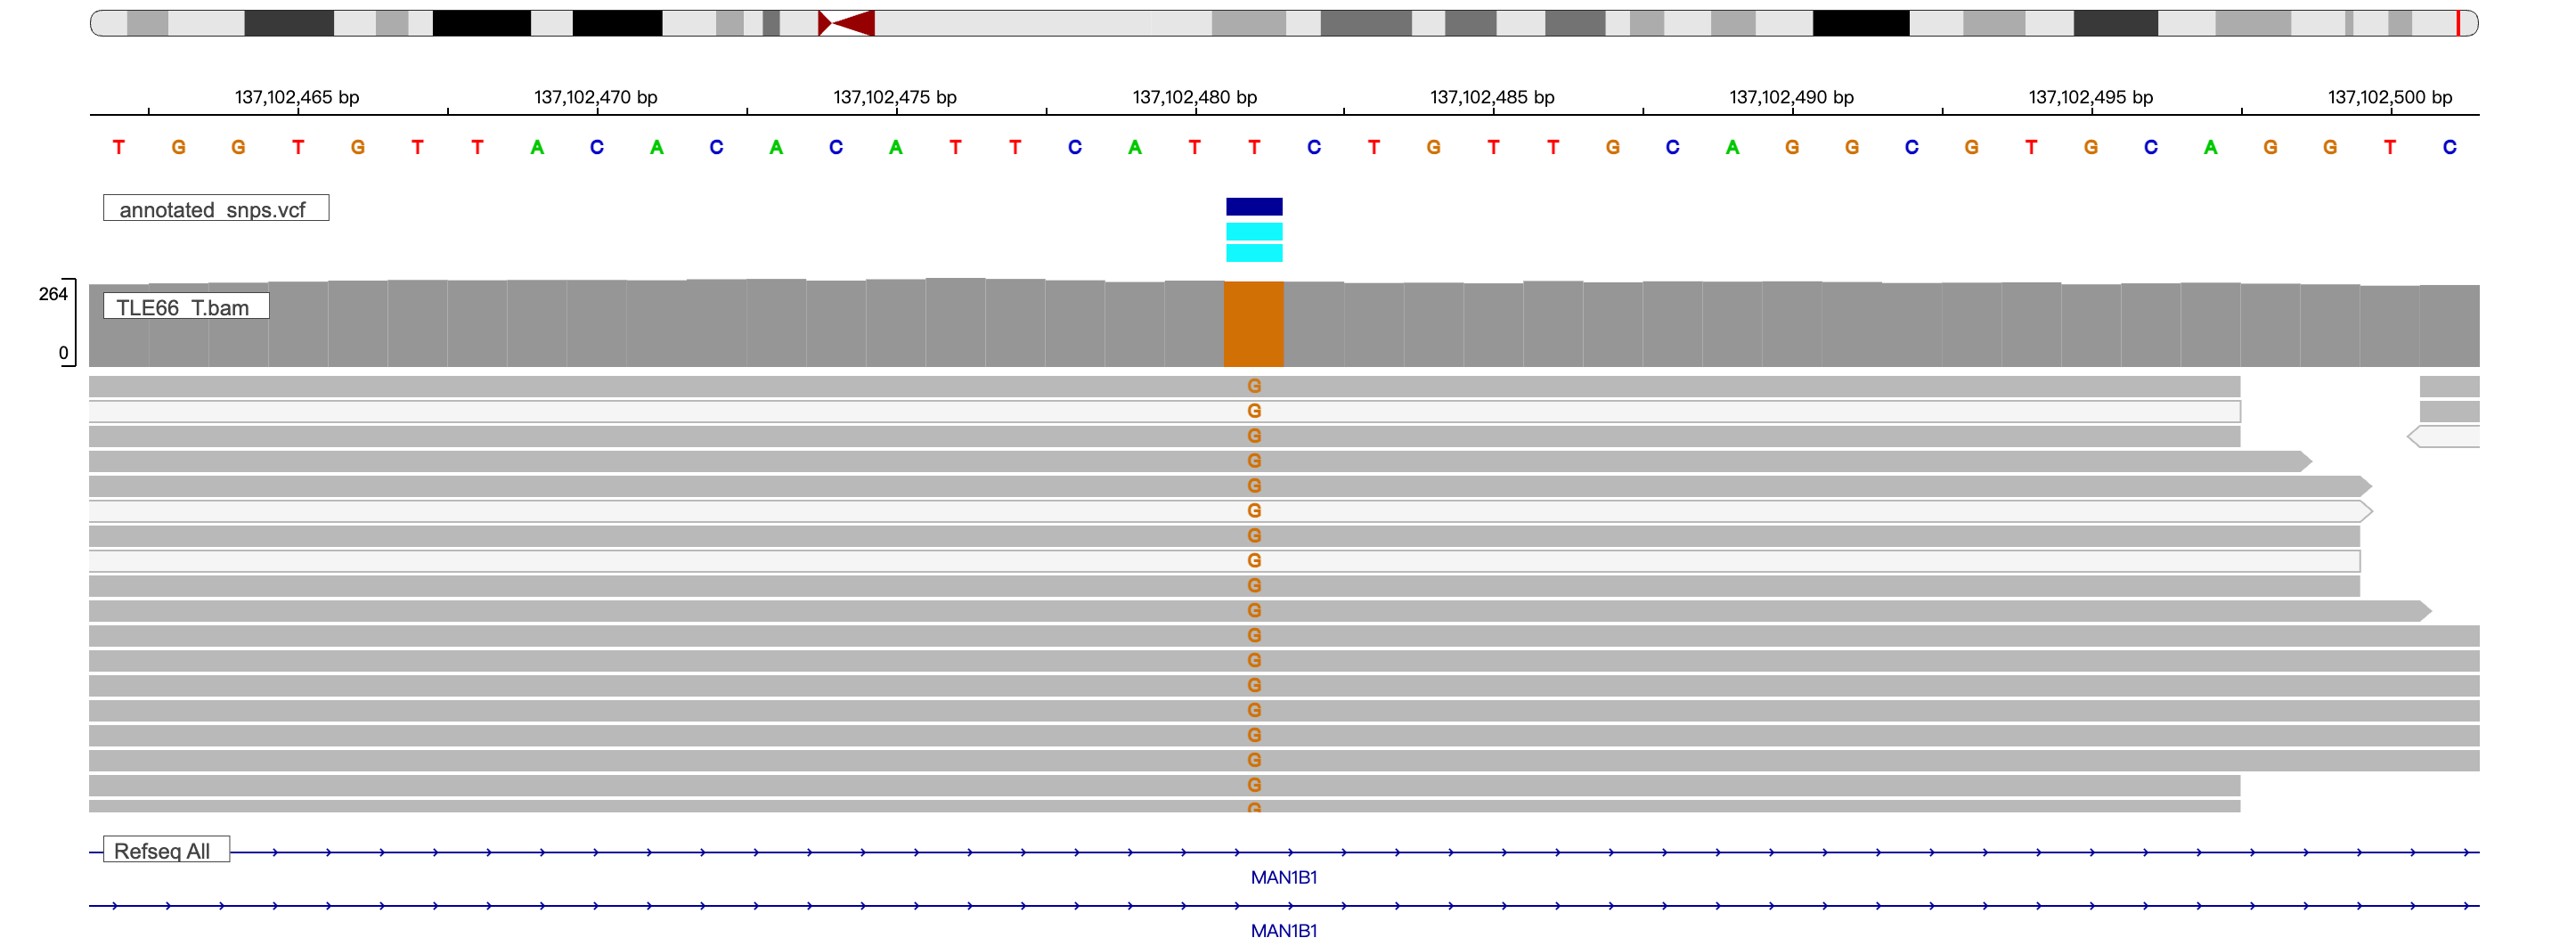
</div>


In [17]:
grep '##INFO=<ID=ANN' annotated_snps.vcf

##INFO=<ID=ANN,Number=.,Type=String,Description="Functional annotations: 'Allele | Annotation | Annotation_Impact | Gene_Name | Gene_ID | Feature_Type | Feature_ID | Transcript_BioType | Rank | HGVS.c | HGVS.p | cDNA.pos / cDNA.length | CDS.pos / CDS.length | AA.pos / AA.length | Distance | ERRORS / WARNINGS / INFO' ">


In [24]:
grep 'HIGH' annotated_snps.vcf | head -1

chr9	127912188	.	G	GC	208.644	.	INDEL;IDV=8;IMF=0.666667;DP=21;VDB=0.559446;SGB=-5.64361;RPBZ=0.0711362;MQBZ=0;BQBZ=-1.64721;SCBZ=0.866025;MQ0F=0;AC=2;AN=4;DP4=8,1,11,1;MQ=60;OLD_VARIANT=chr9:127912188:GCCCC/GCCCCC;ANN=GC|frameshift_variant|HIGH|PPP6C|PPP6C|transcript|NM_001123355.1|protein_coding|8/8|c.792_793insG|p.Asn265fs|1013/4350|792/1029|264/342||,GC|frameshift_variant|HIGH|PPP6C|PPP6C|transcript|NM_002721.5|protein_coding|7/7|c.681_682insG|p.Asn228fs|766/4103|681/918|227/305||,GC|frameshift_variant|HIGH|PPP6C|PPP6C|transcript|NM_001123369.1|protein_coding|6/6|c.615_616insG|p.Asn206fs|836/4173|615/852|205/283||;LOF=(PPP6C|PPP6C|3|1.00)	GT:PL:AD	0/1:159,0,75:4,8	0/1:83,0,75:5,4


In [29]:
grep "137102481" annotated_snps.vcf

chr9	137102481	.	T	G	486.063	.	DP=471;VDB=0.557019;SGB=-1.38629;RPBZ=1.16838;MQBZ=-1.73258;MQSBZ=0.956502;BQBZ=1.66605;SCBZ=0.147431;MQ0F=0.0636943;AC=4;AN=4;DP4=0,1,243,226;MQ=21;ANN=G|intergenic_region|MODIFIER|RNU6ATAC-LINC02247|RNU6ATAC-LINC02247|intergenic_region|RNU6ATAC-LINC02247|||n.137102481T>G||||||	GT:PL:AD	1/1:255,255,0:1,232	1/1:255,255,0:0,236
